# UPI App Complaint Analytics

NLP analysis of 86,056 Google Play reviews of BHIM, Google Pay, Paytm and PhonePe.

**Contents**
1. Data collection (Phase 2)
2. Exploratory data analysis (Phase 3)
3. Text preprocessing (Phase 4)
4. Feature engineering (Phase 5)
5. Sentiment models: baselines and fine-tuned DistilBERT (Phase 6)
6. Complaint themes: BERTopic, business themes and LDA comparison (Phase 7)
7. Business impact: rating drivers, priority matrix, release events, company replies (Phase 8)
8. Final charts and the Streamlit dashboard (Phase 9)

Runs in Google Colab. A GPU is needed only for the transformer cells (Phase 6b and 7a). Set `BASE` in the Drive cell to your own working folder.

## Data collection (Phase 2)
The reviews were scraped with `src/scrape_reviews.py`; the cells below install the scraper and load the collected file.

In [ ]:
!pip install google-play-scraper

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.6 MB/s eta 0:00:00


In [ ]:
!pip install -q google-play-scraper
import time, os, pandas as pd
from google_play_scraper import reviews, Sort
BASE = '/content/drive/MyDrive/upi-complaint-analytics'

TOPUP = {
    'PhonePe':    'com.phonepe.app',
    'Paytm':      'net.one97.paytm',
    'Google Pay': 'com.google.android.apps.nbu.paisa.user',
}
TARGET_LONG = 5000     # stop when this many reviews have 5+ words
MAX_TOTAL = 60000      # safety cap per app

def scrape(app_id, target_long=TARGET_LONG, cap=MAX_TOTAL):
    out, token, n_long = [], None, 0
    while n_long < target_long and len(out) < cap:
        batch, token = reviews(app_id, lang='en', country='in', sort=Sort.NEWEST,
                               count=200, continuation_token=token)
        if not batch:
            break
        out.extend(batch)
        n_long += sum(len(str(r['content'] or '').split()) >= 5 for r in batch)
        if len(out) % 2000 == 0:
            print(f'  {len(out):,} total, {n_long:,} long')
        if token is None:
            break
        time.sleep(1)
    return out

new = []
for name, app_id in TOPUP.items():
    print('Scraping', name)
    rows = scrape(app_id)
    for r in rows:
        r['app'] = name
    new.extend(rows)

new = pd.DataFrame(new)[['app', 'reviewId', 'content', 'score', 'thumbsUpCount',
                         'reviewCreatedVersion', 'at', 'replyContent', 'repliedAt']]
new = new.rename(columns={'reviewId': 'review_id', 'content': 'review_text', 'score': 'rating',
                          'thumbsUpCount': 'helpful_votes', 'reviewCreatedVersion': 'app_version',
                          'at': 'review_date', 'replyContent': 'company_reply', 'repliedAt': 'reply_date'})

old = pd.read_csv(f'{BASE}/data/raw/raw_reviews.csv')
combined = pd.concat([old, new]).drop_duplicates(subset='review_id')
combined.to_csv(f'{BASE}/data/raw/raw_reviews_v2.csv', index=False, encoding='utf-8-sig')

check = pd.read_csv(f'{BASE}/data/raw/raw_reviews_v2.csv', parse_dates=['review_date'])
check['words'] = check['review_text'].fillna('').str.split().str.len()
print(check.shape)
print(check.groupby('app').agg(reviews=('review_id', 'count'),
                               first=('review_date', 'min'),
                               last=('review_date', 'max'),
                               usable_5plus_words=('words', lambda s: (s >= 5).sum())))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.5 MB/s eta 0:00:00
Scraping PhonePe
  2,000 total, 378 long
  4,000 total, 741 long
  6,000 total, 1,048 long
  8,000 total, 1,366 long
  10,000 total, 1,693 long
  12,000 total, 1,999 long
  14,000 total, 2,302 long
  16,000 total, 2,717 long
  18,000 total, 3,019 long
  20,000 total, 3,341 long
  22,000 total, 3,633 long
  24,000 total, 3,956 long
  26,000 total, 4,315 long
  28,000 total, 4,651 long
  30,000 total, 4,977 long
Scraping Paytm
  2,000 total, 251 long
  4,000 total, 516 long
  6,000 total, 844 long
  8,000 total, 1,115 long
  10,000 total, 1,391 long
  12,000 total, 1,725 long
  14,000 total, 2,226 long
  16,000 total, 2,676 long
  18,000 total, 3,096 long
  20,000 total, 3,574 long
  22,000 total, 3,967 long
  24,000 total, 4,350 long
  26,000 total, 4,735 long
Scraping Google Pay
  2,000 total, 610 long
  4,000 total, 1,126 long
  6,000 total, 1,469 long
  8,000 total, 1,905 long
  10,000 total, 2,495 long
 

Cell 3: connect Drive and create the project folders

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = '/content/drive/MyDrive/upi-complaint-analytics'
for sub in ['data/raw', 'data/processed', 'reports/figures', 'dashboard']:
    os.makedirs(f'{BASE}/{sub}', exist_ok=True)

print('raw_reviews.csv still in Colab:', os.path.exists('/content/raw_reviews.csv'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
raw_reviews.csv still in Colab: False


In [ ]:
from google.colab import files
import shutil

uploaded = files.upload()   # a "Choose Files" button appears below the cell
for name in uploaded:
    shutil.move(name, f'{BASE}/data/raw/raw_reviews.csv')
print('In Drive:', os.listdir(f'{BASE}/data/raw'))

Saving raw_reviews.csv to raw_reviews.csv
In Drive: ['raw_reviews.csv']


Cell 4: copy all outputs to Drive, set the seed, check the data

In [ ]:
import shutil, random, numpy as np, pandas as pd

for f in ['raw_reviews.csv', 'dataset_summary.csv']:
    if os.path.exists(f'/content/{f}'):
        shutil.copy(f'/content/{f}', f'{BASE}/data/raw/{f}')
for f in ['chart_rating_distribution.png', 'chart_review_length.png']:
    if os.path.exists(f'/content/{f}'):
        shutil.copy(f'/content/{f}', f'{BASE}/reports/figures/{f}')
print('Saved in Drive:', os.listdir(f'{BASE}/data/raw'))

random.seed(42); np.random.seed(42)

df = pd.read_csv(f'{BASE}/data/raw/raw_reviews.csv', parse_dates=['review_date'])
df['words'] = df['review_text'].fillna('').str.split().str.len()
print(df.shape)
print(df.groupby('app').agg(first=('review_date', 'min'),
                            last=('review_date', 'max'),
                            usable_5plus_words=('words', lambda s: (s >= 5).sum())))

Saved in Drive: ['raw_reviews.csv']
(40000, 10)
                         first                last  usable_5plus_words
app                                                                   
BHIM       2026-06-21 23:57:39 2026-10-14 17:19:26                7029
Google Pay 2026-07-28 06:41:56 2026-10-14 18:46:22                2493
Paytm      2026-09-17 05:27:03 2026-10-14 19:05:21                1456
PhonePe    2026-09-25 02:58:07 2026-10-14 18:43:38                1624


Exploratory data analysis (Phase 3)

Cell A: Load the data and print a profile

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, os
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)

BASE = '/content/drive/MyDrive/upi-complaint-analytics'
FIG = f'{BASE}/reports/figures'
df = pd.read_csv(f'{BASE}/data/raw/raw_reviews_v2.csv', parse_dates=['review_date', 'reply_date'])
df['review_text'] = df['review_text'].fillna('')
df['words'] = df['review_text'].str.split().str.len()
df['is_long'] = df['words'] >= 5
df['in_common'] = df['review_date'].between('2026-08-19', '2026-10-14 23:59:59')

APPS = ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']
COLORS = {'BHIM': '#E4572E', 'Google Pay': '#4C9BE8', 'Paytm': '#17A398', 'PhonePe': '#7B4FBF'}

print(df.shape)
print('\nMissing values:\n', df.isna().sum())
print('\nEmpty reviews:', (df['words'] == 0).sum())
print('Same text posted twice (same app):', df.duplicated(['app', 'review_text']).sum())

summary = df.groupby('app').agg(
    reviews=('review_id', 'count'), avg_rating=('rating', 'mean'),
    pct_1_star=('rating', lambda s: (s == 1).mean() * 100),
    pct_5_star=('rating', lambda s: (s == 5).mean() * 100),
    median_words=('words', 'median'), pct_long=('is_long', lambda s: s.mean() * 100),
    pct_replied=('company_reply', lambda s: s.notna().mean() * 100),
    in_common_window=('in_common', 'sum')).round(1)
print('\n', summary)
summary.to_csv(f'{BASE}/data/processed/eda_summary.csv')

(86056, 12)

Missing values:
 app                  0
review_id            0
review_text          0
rating               0
helpful_votes        0
app_version      13040
review_date          0
company_reply    39999
reply_date       39999
words                0
is_long              0
in_common            0
dtype: int64

Empty reviews: 0
Same text posted twice (same app): 44089

             reviews  avg_rating  pct_1_star  pct_5_star  median_words  pct_long  pct_replied  in_common_window
app                                                                                                           
BHIM          10000         2.7        45.6        29.2          11.0      70.3         96.8              4406
Google Pay    18221         4.0        18.5        65.3           2.0      27.7         11.3              7992
Paytm         27614         4.5        10.4        81.2           2.0      18.2         96.2             19306
PhonePe       30221         4.4         9.3        73.7          

Cell B: rating distribution and review length

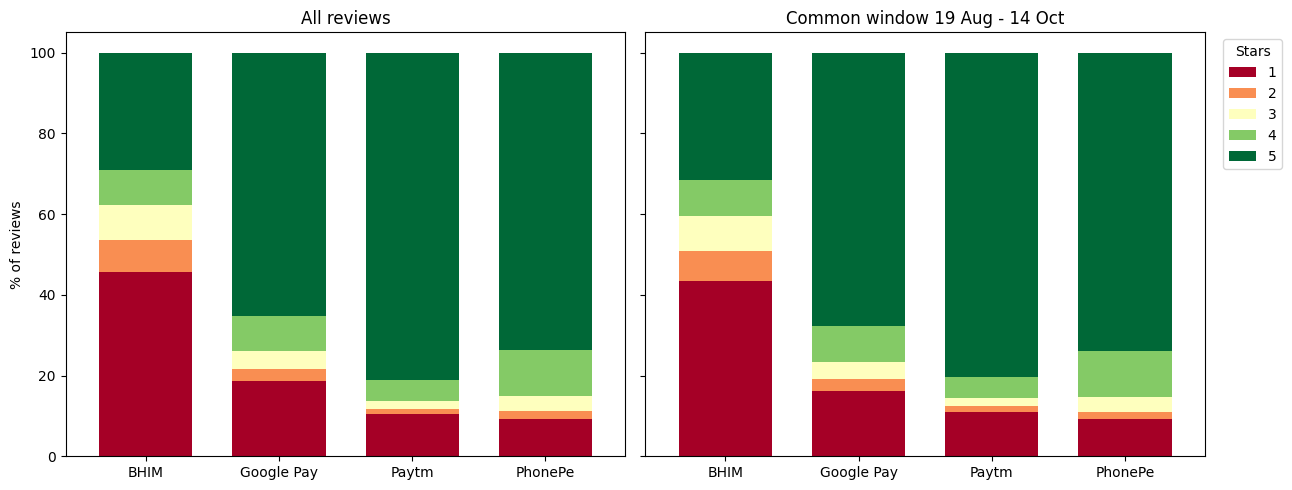

        mean  median
rating              
1       19.0    11.0
2       16.6     8.0
3       11.6     3.0
4        6.1     2.0
5        3.1     2.0


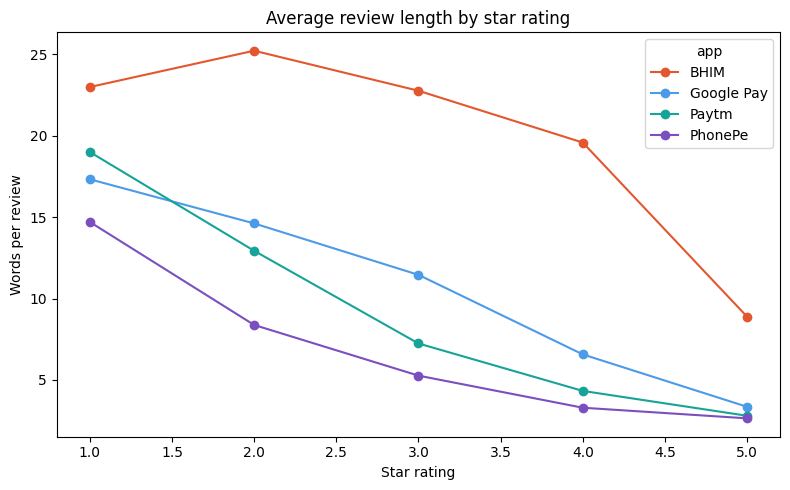

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (label, d) in zip(axes, [('All reviews', df), ('Common window 19 Aug - 14 Oct', df[df.in_common])]):
    dist = pd.crosstab(d['app'], d['rating'], normalize='index') * 100
    dist.loc[APPS].plot(kind='bar', stacked=True, ax=ax, colormap='RdYlGn', width=0.7, legend=False)
    ax.set_title(label); ax.set_xlabel(''); ax.set_ylabel('% of reviews'); ax.tick_params(axis='x', rotation=0)
axes[1].legend(title='Stars', bbox_to_anchor=(1.02, 1))
plt.tight_layout(); plt.savefig(f'{FIG}/01_rating_distribution.png', dpi=150); plt.show()

print(df.groupby('rating')['words'].agg(['mean', 'median']).round(1))
fig, ax = plt.subplots(figsize=(8, 5))
df.groupby(['rating', 'app'])['words'].mean().unstack()[APPS].plot(
    marker='o', ax=ax, color=[COLORS[a] for a in APPS])
ax.set_title('Average review length by star rating'); ax.set_xlabel('Star rating'); ax.set_ylabel('Words per review')
plt.tight_layout(); plt.savefig(f'{FIG}/02_length_by_rating.png', dpi=150); plt.show()

Cell C: Trends over time

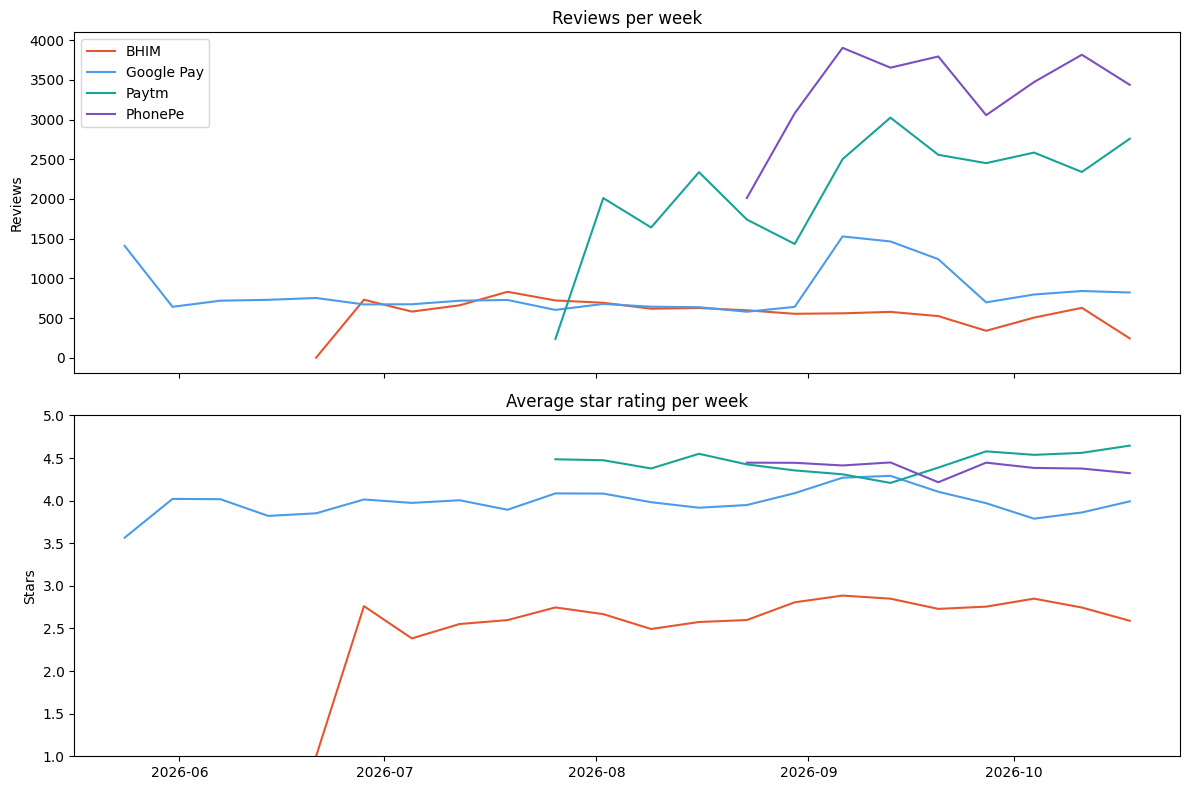

In [ ]:
weekly = (df.set_index('review_date').groupby('app')
            .resample('W')['rating'].agg(['count', 'mean']).reset_index())
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for a in APPS:
    w = weekly[weekly.app == a]
    axes[0].plot(w.review_date, w['count'], label=a, color=COLORS[a])
    axes[1].plot(w.review_date, w['mean'], label=a, color=COLORS[a])
axes[0].set_title('Reviews per week'); axes[0].set_ylabel('Reviews'); axes[0].legend()
axes[1].set_title('Average star rating per week'); axes[1].set_ylabel('Stars'); axes[1].set_ylim(1, 5)
plt.tight_layout(); plt.savefig(f'{FIG}/03_weekly_trends.png', dpi=150); plt.show()

Cell D: Most common 2 words

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
STOP = list(ENGLISH_STOP_WORDS - {'not', 'no', 'never', 'nor', 'without'})   # keep negations!

top = {}
for a in APPS:
    texts = df[(df.app == a) & (df.rating <= 2) & df.is_long]['review_text'].str.lower()
    cv = CountVectorizer(ngram_range=(2, 2), stop_words=STOP, min_df=5)
    X = cv.fit_transform(texts)
    s = pd.Series(X.sum(axis=0).A1, index=cv.get_feature_names_out()).nlargest(15)
    top[a] = [f'{k} ({v})' for k, v in s.items()]
print(pd.DataFrame(top))

                      BHIM             Google Pay                     Paytm                PhonePe
0        not working (497)       google pay (472)         not working (195)        phone pay (137)
1           not able (341)      not working (224)             app not (170)      not working (106)
2            app not (312)          app not (127)           paytm app (132)         phone pe (106)
3           bhim app (311)      bank account (89)     environment not (121)  customer support (85)
4        mobile data (284)         worst app (86)       customer care (119)         worst app (85)
5          worst app (193)          not able (76)  device environment (117)     customer care (83)
6            otp not (185)     customer care (72)         not correct (105)           app not (68)
7      mobile number (169)          upi lite (67)            worst app (96)          raha hai (63)
8          enter otp (150)           pay not (57)     customer support (87)      bank account (55)
9     unab

Cell E: Company replies and app versions

In [ ]:
!pip install -q langdetect
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 0

for a in APPS:
    v = (df[df.app == a].groupby('app_version')
           .agg(reviews=('review_id', 'count'), avg_rating=('rating', 'mean'), first_seen=('review_date', 'min'))
           .query('reviews >= 300').sort_values('first_seen'))
    print(f'\n{a}: {len(v)} versions with 300+ reviews'); print(v.round(2))

r = df[df.company_reply.notna()].copy()
r['reply_hours'] = (r.reply_date - r.review_date).dt.total_seconds() / 3600
print('\nMedian hours until company reply:\n', r.groupby('app')['reply_hours'].median().round(1))
print('\nAvg rating, replied vs not:\n',
      df.assign(replied=df.company_reply.notna()).groupby(['app', 'replied'])['rating'].mean().unstack().round(2))

def lang(t):
    try: return detect(t)
    except Exception: return 'unknown'
sample = df[df.is_long].sample(3000, random_state=42)
sample['lang'] = sample.review_text.apply(lang)
print('\nLanguage mix (sample of 3,000 long reviews):\n', sample.lang.value_counts(normalize=True).head(8).round(3))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 17.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done

BHIM: 7 versions with 300+ reviews
             reviews  avg_rating          first_seen
app_version                                         
4.0.23           344        2.98 2026-06-21 23:57:39
4.0.24          1717        2.52 2026-06-22 00:09:24
4.0.25           475        3.13 2026-07-08 15:02:53
4.0.26          2467        2.62 2026-07-19 16:35:36
4.0.27           786        3.03 2026-08-18 18:16:20
4.0.29          1089        2.87 2026-09-08 13:00:57
4.0.30           456        2.60 2026-09-27 11:50:16

Google Pay: 16 versions with 300+ reviews
                                     reviews  avg_rating          first_seen
app_version                                                                 
331.1.2 (arm64-v8a_release_flutter)     1107        3.62 2026-05-18 08:45:19
332.1.1 (arm64-v8a_release_flutter)      519        4.06 2026-05-21 10:25:11
333.1.1 (arm64

In [ ]:
# Check 1: long reviews that appear more than once (possible spam / copy-paste)
long_dup = df[df.is_long & df.duplicated(['app', 'review_text'], keep=False)]
print('Long reviews appearing more than once:', len(long_dup))
print(long_dup.review_text.value_counts().head(10))

# Check 2: Google Pay's first week, day by day
g = df[(df.app == 'Google Pay') & (df.review_date < '2026-05-26')]
print(g.groupby(g.review_date.dt.date).agg(reviews=('rating', 'size'), avg_rating=('rating', 'mean')).round(2))

# Check 3: are company replies templates? (few unique texts = automated)
rep = df[df.company_reply.notna()]
print(rep.groupby('app').company_reply.agg(replies='size', unique_reply_texts='nunique'))
print(rep[rep.app == 'Paytm'].company_reply.value_counts().head(3))

Long reviews appearing more than once: 104
review_text
this app is very good                         7
best app for online payment                   6
best app for money transfer                   4
nice app easy to use                          4
app is not working properly                   4
best app for upi payment                      3
one of the best app                           2
Outstanding app with extraordinary service    2
very very very nice app                       2
fast and easy to use                          2
Name: count, dtype: int64
             reviews  avg_rating
review_date                     
2026-05-18       472        3.38
2026-05-19       327        3.35
2026-05-20       171        3.58
2026-05-21       129        3.55
2026-05-22       108        3.95
2026-05-23        97        4.09
2026-05-24       105        4.13
2026-05-25        69        3.70
            replies  unique_reply_texts
app                                    
BHIM           9684          

## Text preprocessing (Phase 4)

Cell P1: load the data and set up the dictionaries

In [ ]:
!pip install -q emoji
import re, emoji, pandas as pd, numpy as np, nltk, spacy
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

BASE = '/content/drive/MyDrive/upi-complaint-analytics'
df = pd.read_csv(f'{BASE}/data/raw/raw_reviews_v2.csv', parse_dates=['review_date', 'reply_date'])
df['review_text'] = df['review_text'].fillna('').astype(str)

CONTRACTIONS = [(r"won't", 'will not'), (r"can't", 'can not'), (r"n't\b", ' not'),
                (r"'re\b", ' are'), (r"'ll\b", ' will'), (r"'ve\b", ' have'),
                (r"'m\b", ' am'), (r"'d\b", ' would'), (r"'s\b", '')]

SLANG = {
    'dont': 'do not', 'cant': 'can not', 'wont': 'will not', 'doesnt': 'does not', 'didnt': 'did not',
    'isnt': 'is not', 'wasnt': 'was not', 'arent': 'are not', 'havent': 'have not', 'hasnt': 'has not',
    'couldnt': 'could not', 'shouldnt': 'should not', 'wouldnt': 'would not', 'nt': 'not',
    'pls': 'please', 'plz': 'please', 'plzz': 'please', 'plss': 'please',
    'thx': 'thanks', 'thnx': 'thanks', 'thanku': 'thanks', 'tq': 'thanks',
    'u': 'you', 'ur': 'your', 'msg': 'message', 'acc': 'account', 'acct': 'account', 'amt': 'amount',
    'txn': 'transaction', 'txns': 'transactions', 'trxn': 'transaction', 'transection': 'transaction',
    'transcation': 'transaction', 'tranaction': 'transaction', 'trasaction': 'transaction',
    'transction': 'transaction', 'paymnt': 'payment', 'pyment': 'payment', 'paymet': 'payment',
    'recived': 'received', 'recieved': 'received', 'receved': 'received',
    'wrking': 'working', 'workng': 'working', 'gud': 'good', 'vry': 'very', 'bt': 'but',
}
HINGLISH = {
    'nahi aaya': 'not received', 'nhi aaya': 'not received', 'nahi aya': 'not received',
    'nhi aya': 'not received', 'nahi aa raha': 'not received', 'nhi aa rha': 'not received',
    'kat gaya': 'deducted', 'kat gya': 'deducted', 'kat gaye': 'deducted', 'kat gye': 'deducted',
    'kaat liya': 'deducted', 'kat liya': 'deducted', 'cut gaya': 'deducted', 'cut gya': 'deducted',
    'chal nahi raha': 'not working', 'chal nhi rha': 'not working', 'nahi chal raha': 'not working',
    'nhi chal rha': 'not working', 'kaam nahi': 'not working', 'kaam nhi': 'not working',
    'band ho gaya': 'stopped', 'band ho gya': 'stopped', 'band hai': 'stopped',
    'raha hai': ' ', 'rha hai': ' ', 'rahi hai': ' ', 'rhi hai': ' ',
    'ho raha': ' ', 'ho rha': ' ', 'ho gaya': ' ', 'ho gya': ' ',
    'paisa': 'money', 'paise': 'money', 'paisaa': 'money', 'pese': 'money',
    'wapas': 'back', 'vapas': 'back', 'vaapas': 'back', 'wapis': 'back', 'vapis': 'back',
    'nahi': 'not', 'nahin': 'not', 'nhi': 'not', 'nai': 'not',
    'bekar': 'useless', 'bekaar': 'useless', 'bakwas': 'useless', 'bakwaas': 'useless',
    'ghatiya': 'useless', 'faltu': 'useless',
    'accha': 'good', 'acha': 'good', 'achha': 'good', 'achcha': 'good', 'badhiya': 'good', 'badiya': 'good',
    'bahut': 'very', 'bohot': 'very', 'bhut': 'very', 'bahot': 'very', 'bohut': 'very',
    'kyu': 'why', 'kyun': 'why', 'kyon': 'why', 'kab': 'when', 'kaise': 'how', 'kese': 'how',
    'khata': 'account',
}
BRANDS = {
    'phone pe': 'phonepe', 'phone pay': 'phonepe', 'phonepay': 'phonepe', 'phone-pe': 'phonepe',
    'google pay': 'googlepay', 'g pay': 'googlepay', 'gpay': 'googlepay', 'g-pay': 'googlepay', 'tez': 'googlepay',
    'pay tm': 'paytm',
}
NEGATIONS = {'not', 'no', 'never', 'nor', 'without', 'nothing'}
HINGLISH_STOP = {'hai', 'hain', 'ho', 'ka', 'ki', 'ke', 'se', 'mein', 'ko', 'bhi', 'ye', 'yeh', 'wo', 'woh',
                 'kar', 'karo', 'kiya', 'diya', 'liya', 'tha', 'thi', 'hua', 'hui', 'gaya', 'gya', 'raha',
                 'rha', 'rahi', 'aur', 'ya', 'par', 'ek', 'mera', 'meri', 'mere', 'apna', 'koi', 'kuch',
                 'sab', 'bhai', 'ji'}
BRAND_STOP = {'phonepe', 'googlepay', 'paytm', 'bhim', 'app', 'apps', 'application'}
STOP = (set(stopwords.words('english')) | HINGLISH_STOP | BRAND_STOP) - NEGATIONS

print('Loaded', len(df), 'reviews;', len(SLANG) + len(HINGLISH) + len(BRANDS), 'dictionary entries')

Loaded 86056 reviews; 125 dictionary entries


Cell P2: light cleaning, junk filter and cleaning funnel

In [ ]:
def build_replacer(mapping):
    keys = sorted(mapping, key=len, reverse=True)
    pat = re.compile(r'\b(' + '|'.join(map(re.escape, keys)) + r')\b')
    return lambda t: pat.sub(lambda m: mapping[m.group(1)], t)

replace_words = build_replacer({**BRANDS, **HINGLISH, **SLANG})

def light_clean(t):
    t = t.replace('\u2019', "'").replace('\u2018', "'")
    t = emoji.demojize(t, delimiters=(' ', ' ')).replace('_', ' ')
    t = t.lower()
    t = re.sub(r'[a-z-]*\s?skin\s?tone', ' ', t)
    t = re.sub(r'http\S+|www\.\S+|\S+@\S+|\b\d{10,12}\b', ' ', t)
    t = re.sub(r'([a-z])\1{2,}', r'\1\1', t)
    for pat, rep in CONTRACTIONS:
        t = re.sub(pat, rep, t)
    t = replace_words(t)
    return re.sub(r'\s+', ' ', t).strip()

INDIC = r'[\u0900-\u0DFF]'   # Hindi, Bengali, Punjabi, Gujarati, Odia, Tamil, Telugu, Kannada, Malayalam scripts

df['text_light'] = df['review_text'].apply(light_clean)
df['emojis'] = df['review_text'].apply(lambda t: ''.join(emoji.distinct_emoji_list(t)))
df['words_no_emoji'] = df['review_text'].apply(lambda t: len(emoji.replace_emoji(t, '').split()))
df['is_long'] = df['words_no_emoji'] >= 5
df['has_indic'] = df['review_text'].str.contains(INDIC, regex=True)
latin_words = df['text_light'].str.count(r'[a-z]{2,}')
df['indic_only'] = df['has_indic'] & (latin_words == 0)
df['is_junk'] = (latin_words == 0) & ~df['has_indic']

funnel = df.groupby('app').agg(scraped=('review_id', 'size'),
                               junk_removed=('is_junk', 'sum'),
                               indic_script_only=('indic_only', 'sum'))
funnel['kept'] = funnel['scraped'] - funnel['junk_removed']
usable = df[~df.is_junk & ~df.indic_only]
funnel['english_text_usable'] = usable.groupby('app').size()
funnel['long_usable'] = usable.groupby('app')['is_long'].sum()
funnel.loc['TOTAL'] = funnel.sum()
print(funnel)
print('\nJunk examples:', df[df.is_junk]['review_text'].head(15).tolist())
print('\nIndian-script examples:', df[df.indic_only]['review_text'].head(8).tolist())

df = df[~df.is_junk].copy()

            scraped  junk_removed  indic_script_only   kept  english_text_usable  long_usable
app                                                                                          
BHIM          10000             2                 82   9998                 9916         6951
Google Pay    18221            35                207  18186                17979         4930
Paytm         27614            13                272  27601                27329         4841
PhonePe       30221            27                268  30194                29926         4829
TOTAL         86056            77                829  85979                85150        21551

Junk examples: ['№##', '★★★★★', 'w /L', '1 n......', '₹1,500', 'p ,', '... ..', '🇳\u200c🇮\u200c🇨\u200c🇪\u200c', ', >>A', 'o.k', '(\u3000＾ω＾)(\u3000＾▽＾)( ´;ﾟ;∀;ﾟ;)(\u3000＾ω＾)( =＾ω＾)(ﾟーﾟ*)(*￣∇￣)ノ(*σ>∀<)σ(//∇//)', '𝓷𝓮𝓪𝓳𝓭𝓫𝓾', 'k,', '51//,-6%1u4', '𝓮𝓲𝓽𝓮𝓪𝓱 𝓳𝓪𝓽𝓪𝓿']

Indian-script examples: ['भरोसे मंद', 'उधार देदो कोई लौटा दूंगा ।', 'मोबाइल रिचार

Cell P3: full cleaning (lemmatising), save, and check the result

In [ ]:
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
LEMMA_FIX = {'datum': 'data'}

def full_clean_all(texts):
    texts = [re.sub(r'[^a-z\s]', ' ', t) for t in texts]
    out = []
    for doc in nlp.pipe(texts, batch_size=2000):
        out.append(' '.join(LEMMA_FIX.get(w.lemma_, w.lemma_) for w in doc
                            if w.is_alpha and w.lower_ not in STOP
                            and (len(w) > 2 or w.lower_ in NEGATIONS)))
    return out

no_emoji = df['review_text'].apply(lambda t: light_clean(emoji.replace_emoji(t, ' ')))
df['text_full'] = full_clean_all(no_emoji.tolist())

df.drop(columns=['is_junk']).to_parquet(f'{BASE}/data/processed/clean_reviews.parquet', index=False)
print('Saved', len(df), 'reviews to clean_reviews.parquet')

eng = df[~df.indic_only]
print('English-text reviews with empty text_full:', (eng['text_full'].str.len() == 0).sum())

pd.set_option('display.max_colwidth', 120)
print(eng[eng.is_long & (eng.rating <= 2)].sample(6, random_state=7)[['review_text', 'text_light', 'text_full']])

from sklearn.feature_extraction.text import CountVectorizer
top = {}
for a in ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']:
    t = eng[(eng.app == a) & (eng.rating <= 2) & eng.is_long]['text_full']
    cv = CountVectorizer(ngram_range=(2, 2), min_df=5)
    X = cv.fit_transform(t)
    s = pd.Series(X.sum(axis=0).A1, index=cv.get_feature_names_out()).nlargest(12)
    top[a] = [f'{k} ({v})' for k, v in s.items()]
print(pd.DataFrame(top))

Saved 85979 reviews to clean_reviews.parquet
English-text reviews with empty text_full: 4737
                                                                                                                   review_text  \
44919                                                         worse experience,charges extra for recharge.not at all optimized   
34746                                                                          falthu app unble to type otps app is very waste   
37298  auto reading of messages are not working but all other apps are taking auto reading otp but this does not ....and ev...   
67257  till now they were saying that I need to raise a ticket to report and now they r asking me to login to raise a ticke...   
80875                                                                       Aaj thak ek rupaayi kaa bii reward nahi milgaya...   
33687  Could you please explain what type of scam this is? I'm trying to delete my UPI Lite account, but the app keeps fail... 

Feature engineering (Phase 5)

Cell F1: sentiment labels and the fixed data split

In [ ]:
import pandas as pd, numpy as np, re, emoji
from sklearn.model_selection import train_test_split
BASE = '/content/drive/MyDrive/upi-complaint-analytics'

df = pd.read_parquet(f'{BASE}/data/processed/clean_reviews.parquet')
data = df[~df.indic_only].copy().reset_index(drop=True)      # English-text reviews only

# Labels from star ratings: 1-2 = negative, 3 = neutral, 4-5 = positive
data['label3'] = pd.cut(data.rating, bins=[0, 2, 3, 5],
                        labels=['negative', 'neutral', 'positive']).astype(str)
data['label2'] = data.label3.where(data.label3 != 'neutral')   # empty for 3-star (binary version)

# 70 / 15 / 15 split, balanced by app AND label, fixed with random_state=42
strat = data.app + '_' + data.label3
train_idx, temp_idx = train_test_split(data.index, test_size=0.30, stratify=strat, random_state=42)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=strat[temp_idx], random_state=42)
data['split'] = 'train'
data.loc[val_idx, 'split'] = 'val'
data.loc[test_idx, 'split'] = 'test'

print(data.split.value_counts())
print('\nLabel share per split:\n', pd.crosstab(data.split, data.label3, normalize='index').round(3))
print('\nLabel share per app:\n', pd.crosstab(data.app, data.label3, normalize='index').round(3))

split
train    59605
test     12773
val      12772
Name: count, dtype: int64

Label share per split:
 label3  negative  neutral  positive
split                              
test       0.185    0.039     0.776
train      0.185    0.039     0.776
val        0.185    0.039     0.776

Label share per app:
 label3      negative  neutral  positive
app                                    
BHIM           0.536    0.086     0.377
Google Pay     0.218    0.043     0.739
Paytm          0.118    0.019     0.863
PhonePe        0.110    0.038     0.851


Cell F2: TF-IDF features

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import scipy.sparse as sp, joblib

def emoji_tokens(e):
    return ' '.join('emj_' + re.sub(r'\W+', '_', emoji.demojize(x).strip(':')) for x in e) if e else ''

# text_full + emojis as single tokens + "ok" put back (these were the empty-text cases)
data['tfidf_text'] = (data.text_full + ' ' + data.emojis.fillna('').apply(emoji_tokens)
                      + np.where(data.text_light.str.contains(r'\bok\b'), ' ok', '')).str.strip()
print('Reviews still empty for TF-IDF:', (data.tfidf_text == '').sum())

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, max_features=20000, sublinear_tf=True)
tfidf.fit(data.loc[data.split == 'train', 'tfidf_text'])        # learn vocabulary from TRAIN only
X = tfidf.transform(data.tfidf_text)
print('TF-IDF matrix (reviews x features):', X.shape)

sp.save_npz(f'{BASE}/data/processed/tfidf_X.npz', X)
joblib.dump(tfidf, f'{BASE}/data/processed/tfidf_vectorizer.joblib')

tr = (data.split == 'train').values
vocab = np.array(tfidf.get_feature_names_out())
for lab in ['negative', 'positive']:
    m = np.asarray(X[tr & (data.label3 == lab).values].mean(axis=0)).ravel()
    print(f'\nTop terms in {lab} reviews:', ', '.join(vocab[m.argsort()[::-1][:20]]))

Reviews still empty for TF-IDF: 398
TF-IDF matrix (reviews x features): (85150, 6777)

Top terms in negative reviews: not, bad, good, work, not work, use, no, payment, open, otp, time, useless, please, slow, nice, money, show, issue, update, unable

Top terms in positive reviews: good, nice, emj_thumbs_up, super, ok, good emj_thumbs_up, well, excellent, nice emj_thumbs_up, payment, service, thank, great, fast, emj_smiling_face_with_smiling_eyes, easy, good service, experience, aap, use


Cell F3: VADER score, metadata features, and save

In [ ]:
!pip install -q vaderSentiment
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()
data['vader'] = data.text_light.apply(lambda t: sia.polarity_scores(t)['compound'])

orig = data.review_text
MONEY = r'\b(?:money|amount|rupees?|rs|inr|refund\w*|deduct\w*|debit\w*|credit\w*|balance|cashback)\b|₹'
data['n_words'] = data.words_no_emoji
data['n_exclaim'] = orig.str.count('!')
letters = orig.str.count(r'[A-Za-z]')
data['caps_ratio'] = (orig.str.count(r'[A-Z]') / letters.replace(0, np.nan)).fillna(0).round(3)
data['has_money'] = data.text_light.str.contains(MONEY, regex=True).astype(int)
data['has_negation'] = data.text_light.str.contains(r'\b(?:not|no|never|nothing)\b', regex=True).astype(int)
data['n_emojis'] = orig.apply(emoji.emoji_count)
data['has_reply'] = data.company_reply.notna().astype(int)   # for business analysis only, NOT a model input

feats = ['vader', 'n_words', 'n_exclaim', 'caps_ratio', 'has_money', 'has_negation', 'n_emojis', 'helpful_votes']
print('Spearman correlation with star rating:\n',
      data[feats + ['rating']].corr(method='spearman')['rating'].drop('rating').round(3).sort_values())
print('\nAverages by star rating:\n',
      data.groupby('rating')[['vader', 'n_words', 'has_money', 'has_negation', 'n_emojis']].mean().round(2))

data.to_parquet(f'{BASE}/data/processed/model_data.parquet', index=False)
print('\nSaved model_data.parquet:', data.shape)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 4.5 MB/s eta 0:00:00
Spearman correlation with star rating:
 has_negation    -0.521
n_words         -0.456
has_money       -0.248
helpful_votes   -0.235
caps_ratio      -0.210
n_exclaim       -0.062
n_emojis         0.085
vader            0.423
Name: rating, dtype: float64

Averages by star rating:
         vader  n_words  has_money  has_negation  n_emojis
rating                                                   
1       -0.13    19.00       0.17          0.54      0.25
2        0.08    16.54       0.12          0.43      0.14
3        0.24    11.54       0.08          0.26      0.18
4        0.39     6.03       0.04          0.09      0.23
5        0.43     2.99       0.02          0.03      0.30

Saved model_data.parquet: (85150, 28)


Phase 6a – Baseline Sentiment Models

Cell S1: load everything and set up the evaluation

In [ ]:
import pandas as pd, numpy as np, scipy.sparse as sp, joblib, torch, os
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

BASE = '/content/drive/MyDrive/upi-complaint-analytics'
PROC = f'{BASE}/data/processed'
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NOT AVAILABLE - switch runtime!')

data = pd.read_parquet(f'{PROC}/model_data.parquet')
X_tfidf = sp.load_npz(f'{PROC}/tfidf_X.npz')
assert X_tfidf.shape[0] == len(data), 'Row mismatch between data and TF-IDF!'
tr, va, te = [(data.split == s).values for s in ['train', 'val', 'test']]

RESULTS_FILE = f'{BASE}/reports/model_results.csv'
results = pd.read_csv(RESULTS_FILE).to_dict('records') if os.path.exists(RESULTS_FILE) else []

def evaluate(model_name, target, y_true, y_pred):
    labels = ['negative', 'neutral', 'positive'] if target == 'label3' else ['negative', 'positive']
    f1s = f1_score(y_true, y_pred, labels=labels, average=None)
    row = {'model': model_name, 'task': '3-class' if target == 'label3' else '2-class',
           'accuracy': round(accuracy_score(y_true, y_pred), 3), 'macro_f1': round(f1s.mean(), 3),
           **{f'f1_{l}': round(f, 3) for l, f in zip(labels, f1s)}}
    results[:] = [r for r in results if not (r['model'] == model_name and r['task'] == row['task'])]
    results.append(row)
    pd.DataFrame(results).to_csv(RESULTS_FILE, index=False)
    return row

print('Train / val / test:', tr.sum(), va.sum(), te.sum())

GPU: Tesla T4
Train / val / test: 59605 12772 12773


Cell S2: Model 1, VADER (rule-based, no training)

In [ ]:
def vader_3(c):
    return 'positive' if c > 0.05 else ('negative' if c < -0.05 else 'neutral')

for target in ['label3', 'label2']:
    m = te & data[target].notna().values
    scores = data.loc[m, 'vader']
    pred = scores.apply(vader_3) if target == 'label3' else np.where(scores >= 0, 'positive', 'negative')
    print(evaluate('VADER', target, data.loc[m, target], pred))

{'model': 'VADER', 'task': '3-class', 'accuracy': 0.747, 'macro_f1': np.float64(0.506), 'f1_negative': np.float64(0.564), 'f1_neutral': np.float64(0.08), 'f1_positive': np.float64(0.872)}
{'model': 'VADER', 'task': '2-class', 'accuracy': 0.876, 'macro_f1': np.float64(0.753), 'f1_negative': np.float64(0.579), 'f1_positive': np.float64(0.927)}


Cell S3: Model 2, TF-IDF + Logistic Regression (classic machine learning)

In [ ]:
def train_lr(X, model_name, Cs=(0.1, 0.3, 1, 3, 10)):
    models = {}
    for target in ['label3', 'label2']:
        ok = data[target].notna().values
        y = data[target].values
        val_scores = {}
        for C in Cs:                                   # tune on VALIDATION set
            clf = LogisticRegression(C=C, max_iter=3000, class_weight='balanced')
            clf.fit(X[tr & ok], y[tr & ok])
            val_scores[C] = f1_score(y[va & ok], clf.predict(X[va & ok]), average='macro')
        best_C = max(val_scores, key=val_scores.get)
        print(f'{model_name} [{target}] val macro F1 by C:',
              {k: round(v, 3) for k, v in val_scores.items()}, '-> best C =', best_C)
        clf = LogisticRegression(C=best_C, max_iter=3000, class_weight='balanced').fit(X[tr & ok], y[tr & ok])
        print('  TEST:', evaluate(model_name, target, y[te & ok], clf.predict(X[te & ok])))
        models[target] = clf
    return models

lr_tfidf = train_lr(X_tfidf, 'TF-IDF + LogReg')
joblib.dump(lr_tfidf, f'{PROC}/lr_tfidf.joblib')

vocab = np.array(joblib.load(f'{PROC}/tfidf_vectorizer.joblib').get_feature_names_out())
clf = lr_tfidf['label3']
for i, cls in enumerate(clf.classes_):
    print(f'\nWords that most push towards {cls.upper()}:',
          ', '.join(vocab[np.argsort(clf.coef_[i])[::-1][:20]]))

TF-IDF + LogReg [label3] val macro F1 by C: {0.1: 0.602, 0.3: 0.6, 1: 0.598, 3: 0.591, 10: 0.586} -> best C = 0.1
  TEST: {'model': 'TF-IDF + LogReg', 'task': '3-class', 'accuracy': 0.824, 'macro_f1': np.float64(0.601), 'f1_negative': np.float64(0.746), 'f1_neutral': np.float64(0.153), 'f1_positive': np.float64(0.903)}
TF-IDF + LogReg [label2] val macro F1 by C: {0.1: 0.826, 0.3: 0.867, 1: 0.871, 3: 0.871, 10: 0.872} -> best C = 10
  TEST: {'model': 'TF-IDF + LogReg', 'task': '2-class', 'accuracy': 0.921, 'macro_f1': np.float64(0.877), 'f1_negative': np.float64(0.804), 'f1_positive': np.float64(0.95)}

Words that most push towards NEGATIVE: not, bad, useless, fraud, unable, waste, poor, even, otp, fake, bad experience, worst, show, scam, emj_thumbs_down, bed, login, never, wrost, ever

Words that most push towards NEUTRAL: sometimes, not bad, slow, share, average, improve, lag, please, need, thik, jata, screen, emj_wilted_flower, check, good help, overall, not, option, protect, also

W

Cell S4: Model 3, sentence embeddings + Logistic Regression (uses the GPU)

In [ ]:
!pip install -q sentence-transformers
from sentence_transformers import SentenceTransformer

texts = data.text_light.tolist()
EMB = {}
for name, model_id in [('MiniLM-en', 'all-MiniLM-L6-v2'),
                       ('MiniLM-multilingual', 'paraphrase-multilingual-MiniLM-L12-v2')]:
    path = f'{PROC}/emb_{name}.npy'
    if os.path.exists(path):
        EMB[name] = np.load(path)
    else:
        enc = SentenceTransformer(model_id, device='cuda')
        EMB[name] = enc.encode(texts, batch_size=256, show_progress_bar=True, convert_to_numpy=True)
        np.save(path, EMB[name])
    print(name, EMB[name].shape)

for name, E in EMB.items():
    train_lr(E, f'Embeddings {name} + LogReg', Cs=(0.1, 1, 10))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/333 [00:00<?, ?it/s]

MiniLM-multilingual (85150, 384)
Embeddings MiniLM-en + LogReg [label3] val macro F1 by C: {0.1: 0.59, 1: 0.59, 10: 0.587} -> best C = 0.1
  TEST: {'model': 'Embeddings MiniLM-en + LogReg', 'task': '3-class', 'accuracy': 0.808, 'macro_f1': np.float64(0.591), 'f1_negative': np.float64(0.724), 'f1_neutral': np.float64(0.153), 'f1_positive': np.float64(0.897)}
Embeddings MiniLM-en + LogReg [label2] val macro F1 by C: {0.1: 0.858, 1: 0.86, 10: 0.861} -> best C = 10
  TEST: {'model': 'Embeddings MiniLM-en + LogReg', 'task': '2-class', 'accuracy': 0.908, 'macro_f1': np.float64(0.863), 'f1_negative': np.float64(0.784), 'f1_positive': np.float64(0.941)}
Embeddings MiniLM-multilingual + LogReg [label3] val macro F1 by C: {0.1: 0.595, 1: 0.591, 10: 0.592} -> best C = 0.1
  TEST: {'model': 'Embeddings MiniLM-multilingual + LogReg', 'task': '3-class', 'accuracy': 0.811, 'macro_f1': np.float64(0.596), 'f1_negative': np.float64(0.736), 'f1_neutral': np.float64(0.152), 'f1_positive': np.float64(0.899

Cell S5: comparison table so far

In [ ]:
pd.set_option('display.width', 200)
print(pd.DataFrame(results).sort_values(['task', 'macro_f1']).to_string(index=False))

                                  model    task  accuracy  macro_f1  f1_negative  f1_neutral  f1_positive
                                  VADER 2-class     0.876     0.753        0.579         NaN        0.927
          Embeddings MiniLM-en + LogReg 2-class     0.908     0.863        0.784         NaN        0.941
Embeddings MiniLM-multilingual + LogReg 2-class     0.912     0.868        0.792         NaN        0.944
                        TF-IDF + LogReg 2-class     0.921     0.877        0.804         NaN        0.950
                                  VADER 3-class     0.747     0.506        0.564       0.080        0.872
          Embeddings MiniLM-en + LogReg 3-class     0.808     0.591        0.724       0.153        0.897
Embeddings MiniLM-multilingual + LogReg 3-class     0.811     0.596        0.736       0.152        0.899
                        TF-IDF + LogReg 3-class     0.824     0.601        0.746       0.153        0.903


In [ ]:
lr_tfidf = train_lr(X_tfidf, 'TF-IDF + LogReg', Cs=(0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100))
joblib.dump(lr_tfidf, f'{PROC}/lr_tfidf.joblib')
print(pd.DataFrame(results).sort_values(['task', 'macro_f1']).to_string(index=False))

TF-IDF + LogReg [label3] val macro F1 by C: {0.01: 0.54, 0.03: 0.568, 0.1: 0.602, 0.3: 0.6, 1: 0.598, 3: 0.591, 10: 0.586, 30: 0.582, 100: 0.577} -> best C = 0.1
  TEST: {'model': 'TF-IDF + LogReg', 'task': '3-class', 'accuracy': 0.824, 'macro_f1': np.float64(0.601), 'f1_negative': np.float64(0.746), 'f1_neutral': np.float64(0.153), 'f1_positive': np.float64(0.903)}
TF-IDF + LogReg [label2] val macro F1 by C: {0.01: 0.758, 0.03: 0.797, 0.1: 0.826, 0.3: 0.867, 1: 0.871, 3: 0.871, 10: 0.872, 30: 0.87, 100: 0.862} -> best C = 10
  TEST: {'model': 'TF-IDF + LogReg', 'task': '2-class', 'accuracy': 0.921, 'macro_f1': np.float64(0.877), 'f1_negative': np.float64(0.804), 'f1_positive': np.float64(0.95)}
                                  model    task  accuracy  macro_f1  f1_negative  f1_neutral  f1_positive
                                  VADER 2-class     0.876     0.753        0.579         NaN        0.927
          Embeddings MiniLM-en + LogReg 2-class     0.908     0.863        0.784   

Phase 6b – Fine-tuned DistilBERT

Cell B1: setup (self-contained, so it works even after a restart)

In [ ]:
!pip install -q datasets
import os, numpy as np, pandas as pd, torch
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

BASE = '/content/drive/MyDrive/upi-complaint-analytics'
PROC = f'{BASE}/data/processed'
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NOT AVAILABLE - switch runtime!')

data = pd.read_parquet(f'{PROC}/model_data.parquet')
RESULTS_FILE = f'{BASE}/reports/model_results.csv'
results = pd.read_csv(RESULTS_FILE).to_dict('records') if os.path.exists(RESULTS_FILE) else []

def evaluate(model_name, target, y_true, y_pred):
    labels = ['negative', 'neutral', 'positive'] if target == 'label3' else ['negative', 'positive']
    f1s = f1_score(y_true, y_pred, labels=labels, average=None)
    row = {'model': model_name, 'task': '3-class' if target == 'label3' else '2-class',
           'accuracy': round(accuracy_score(y_true, y_pred), 3), 'macro_f1': round(f1s.mean(), 3),
           **{f'f1_{l}': round(f, 3) for l, f in zip(labels, f1s)}}
    results[:] = [r for r in results if not (r['model'] == model_name and r['task'] == row['task'])]
    results.append(row)
    pd.DataFrame(results).to_csv(RESULTS_FILE, index=False)
    return row

print(len(data), 'reviews loaded;', len(results), 'earlier results found')

GPU: Tesla T4
85150 reviews loaded; 8 earlier results found


Cell B2: the training function

In [ ]:
import math, inspect
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, set_seed)

MODEL = 'distilbert-base-uncased'
tok = AutoTokenizer.from_pretrained(MODEL)

class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        loss = torch.nn.functional.cross_entropy(
            outputs.logits, labels, weight=self.class_weights.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss

def make_args(**kw):
    allowed = inspect.signature(TrainingArguments.__init__).parameters
    dropped = [k for k in kw if k not in allowed]
    if dropped:
        print('Skipped settings not supported by this transformers version:', dropped)
    return TrainingArguments(**{k: v for k, v in kw.items() if k in allowed})

def run_bert(target, epochs=3, batch=32):
    set_seed(42)
    labels = ['negative', 'neutral', 'positive'] if target == 'label3' else ['negative', 'positive']
    l2i = {l: i for i, l in enumerate(labels)}
    d = data[data[target].notna()]

    def to_ds(split):
        part = d[d.split == split]
        ds = Dataset.from_dict({'text': part.text_light.tolist(), 'labels': part[target].map(l2i).tolist()})
        return ds.map(lambda b: tok(b['text'], truncation=True, max_length=128),
                      batched=True, remove_columns=['text'])
    train_ds, val_ds, test_ds = to_ds('train'), to_ds('val'), to_ds('test')

    y_tr = d[d.split == 'train'][target].map(l2i).values
    w = np.sqrt(compute_class_weight('balanced', classes=np.arange(len(labels)), y=y_tr))
    w = torch.tensor(w, dtype=torch.float)
    print(target, 'class weights:', dict(zip(labels, w.numpy().round(2))))

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL, num_labels=len(labels), id2label=dict(enumerate(labels)), label2id=l2i)

    def metrics(p):
        pred = p.predictions.argmax(-1)
        return {'f1_macro': f1_score(p.label_ids, pred, average='macro'),
                'accuracy': accuracy_score(p.label_ids, pred)}

    total_steps = math.ceil(len(train_ds) / batch) * epochs
    args = make_args(
        output_dir=f'/content/bert_{target}', num_train_epochs=epochs, learning_rate=2e-5,
        per_device_train_batch_size=batch, per_device_eval_batch_size=128,
        weight_decay=0.01, warmup_steps=int(0.06 * total_steps),
        eval_strategy='epoch', save_strategy='epoch', save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model='f1_macro', greater_is_better=True,
        fp16=True, seed=42, report_to='none', logging_steps=200)

    trainer = WeightedTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                              data_collator=DataCollatorWithPadding(tok), compute_metrics=metrics,
                              class_weights=w)
    trainer.train()

    pred = trainer.predict(test_ds).predictions.argmax(-1)
    y_true = [labels[i] for i in test_ds['labels']]
    print('TEST:', evaluate('DistilBERT (fine-tuned)', target, y_true, [labels[i] for i in pred]))

    save_dir = f'{PROC}/distilbert_{target}'
    trainer.save_model(save_dir); tok.save_pretrained(save_dir)
    print('Model saved to', save_dir)
    return trainer, labels

Cell B3: train the 3-class model (~20 min)

In [ ]:
trainer3, labels3 = run_bert('label3')

Map:   0%|          | 0/59605 [00:00<?, ? examples/s]

Map:   0%|          | 0/12772 [00:00<?, ? examples/s]

Map:   0%|          | 0/12773 [00:00<?, ? examples/s]

label3 class weights: {'negative': np.float32(1.34), 'neutral': np.float32(2.94), 'positive': np.float32(0.66)}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TEST: {'model': 'DistilBERT (fine-tuned)', 'task': '3-class', 'accuracy': 0.889, 'macro_f1': np.float64(0.643), 'f1_negative': np.float64(0.791), 'f1_neutral': np.float64(0.193), 'f1_positive': np.float64(0.944)}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to /content/drive/MyDrive/upi-complaint-analytics/data/processed/distilbert_label3


In [ ]:
print(trainer3.state.best_model_checkpoint)

/content/bert_label3/checkpoint-3726


Cell B4: train the 2-class model (~20 min) and show the full comparison

In [ ]:
trainer2, labels2 = run_bert('label2')
pd.set_option('display.width', 200)
print(pd.DataFrame(results).sort_values(['task', 'macro_f1']).to_string(index=False))

Map:   0%|          | 0/57303 [00:00<?, ? examples/s]

Map:   0%|          | 0/12278 [00:00<?, ? examples/s]

Map:   0%|          | 0/12280 [00:00<?, ? examples/s]

label2 class weights: {'negative': np.float32(1.61), 'positive': np.float32(0.79)}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TEST: {'model': 'DistilBERT (fine-tuned)', 'task': '2-class', 'accuracy': 0.935, 'macro_f1': np.float64(0.896), 'f1_negative': np.float64(0.832), 'f1_positive': np.float64(0.96)}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to /content/drive/MyDrive/upi-complaint-analytics/data/processed/distilbert_label2
                                  model    task  accuracy  macro_f1  f1_negative  f1_neutral  f1_positive
                                  VADER 2-class     0.876     0.753        0.579         NaN        0.927
          Embeddings MiniLM-en + LogReg 2-class     0.908     0.863        0.784         NaN        0.941
Embeddings MiniLM-multilingual + LogReg 2-class     0.912     0.868        0.792         NaN        0.944
                        TF-IDF + LogReg 2-class     0.921     0.877        0.804         NaN        0.950
                DistilBERT (fine-tuned) 2-class     0.935     0.896        0.832         NaN        0.960
                                  VADER 3-class     0.747     0.506        0.564       0.080        0.872
          Embeddings MiniLM-en + LogReg 3-class     0.808     0.591        0.724       0.153        0.897
Embeddings MiniLM-multilingual + LogReg 3-class     0.811

Cell B5: predict all 85,150 reviews, confusion matrix, error sample

In [ ]:
all_ds = Dataset.from_dict({'text': data.text_light.tolist()}).map(
    lambda b: tok(b['text'], truncation=True, max_length=128), batched=True, remove_columns=['text'])
probs = torch.softmax(torch.tensor(trainer3.predict(all_ds).predictions), dim=-1).numpy()

data['bert_label'] = [labels3[i] for i in probs.argmax(1)]
data['bert_conf'] = probs.max(1).round(3)
for i, l in enumerate(labels3):
    data[f'p_{l}'] = probs[:, i].round(3)
data.to_parquet(f'{PROC}/reviews_with_sentiment.parquet', index=False)
print('Saved reviews_with_sentiment.parquet')

te = data.split == 'test'
cm = pd.DataFrame(confusion_matrix(data.loc[te, 'label3'], data.loc[te, 'bert_label'], labels=labels3),
                  index=[f'true {l}' for l in labels3], columns=[f'pred {l}' for l in labels3])
print('\nConfusion matrix (test set):\n', cm)
print('\nMacro F1 by app (test set):\n',
      data[te].groupby('app').apply(lambda g: f1_score(g.label3, g.bert_label, average='macro')).round(3))
print('\nShare of all reviews where stars and model disagree:', round((data.label3 != data.bert_label).mean(), 3))

pd.set_option('display.max_colwidth', 150)
err = data[te & (data.label3 != data.bert_label) & data.is_long].sample(25, random_state=1)
print(err[['app', 'rating', 'bert_label', 'bert_conf', 'review_text']].to_string())

Map:   0%|          | 0/85150 [00:00<?, ? examples/s]

Saved reviews_with_sentiment.parquet

Confusion matrix (test set):
                pred negative  pred neutral  pred positive
true negative           1832           169            365
true neutral             135            90            268
true positive            301           181           9432

Macro F1 by app (test set):
 app
BHIM          0.654
Google Pay    0.626
Paytm         0.612
PhonePe       0.595
dtype: float64

Share of all reviews where stars and model disagree: 0.095
              app  rating bert_label  bert_conf                                                                                                                                                                                                                                                                                                                                                                                                                review_text
37711        BHIM       5    neutral      0.662     

/tmp/ipykernel_1555/1178867018.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  data[te].groupby('app').apply(lambda g: f1_score(g.label3, g.bert_label, average='macro')).round(3))


Phase 7a – Topic Modelling (BERTopic)

Cell T1: select the complaint reviews

In [ ]:
!pip install -q bertopic
import pandas as pd, numpy as np, os
pd.set_option('display.max_colwidth', 100); pd.set_option('display.width', 220)

BASE = '/content/drive/MyDrive/upi-complaint-analytics'
PROC = f'{BASE}/data/processed'
data = pd.read_parquet(f'{PROC}/reviews_with_sentiment.parquet')
emb = np.load(f'{PROC}/emb_MiniLM-multilingual.npy')
assert len(emb) == len(data), 'Row mismatch between reviews and embeddings!'

data['is_complaint'] = (data.rating <= 2) | (data.bert_label == 'negative')
mask = (data.is_complaint & data.is_long & (data.text_full.str.split().str.len() >= 3)).values
docs_df = data[mask].copy()
emb_c = emb[mask]

print('All complaints:', data.is_complaint.sum())
print('Hidden complaints (4-5 stars, model says negative):',
      ((data.rating >= 4) & (data.bert_label == 'negative')).sum())
print('Long complaints used for topic modelling:', mask.sum())
print(docs_df.app.value_counts())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 4.4 MB/s eta 0:00:00
All complaints: 18063
Hidden complaints (4-5 stars, model says negative): 1667
Long complaints used for topic modelling: 12202
app
BHIM          5006
Google Pay    2826
Paytm         2468
PhonePe       1902
Name: count, dtype: int64


Cell T2: fit BERTopic

In [ ]:
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer

umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=42)
hdbscan_model = HDBSCAN(min_cluster_size=60, min_samples=10, metric='euclidean',
                        cluster_selection_method='eom', prediction_data=True)
vectorizer = CountVectorizer(ngram_range=(1, 2), min_df=5)

topic_model = BERTopic(umap_model=umap_model, hdbscan_model=hdbscan_model,
                       vectorizer_model=vectorizer, top_n_words=10, verbose=True)
docs = docs_df.text_full.tolist()
topics, _ = topic_model.fit_transform(docs, embeddings=emb_c)

info = topic_model.get_topic_info()
print('\nTopics found:', len(info) - 1, '| share of outliers (topic -1):', round((np.array(topics) == -1).mean(), 3))
print(info[['Topic', 'Count', 'Name']].to_string(index=False))

2026-10-19 17:07:08,446 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-19 17:08:34,881 - BERTopic - Dimensionality - Completed ✓
2026-10-19 17:08:34,883 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-19 17:08:35,449 - BERTopic - Cluster - Completed ✓
2026-10-19 17:08:35,458 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-19 17:08:35,876 - BERTopic - Representation - Completed ✓



Topics found: 40 | share of outliers (topic -1): 0.231
 Topic  Count                                                     Name
    -1   2818                                        -1_not_use_bad_no
     0   1216                                   0_useless_hota_not_aap
     1    718                              1_otp_auto_otp not_manually
     2    589                               2_google_account_money_not
     3    530                      3_payment_money_transaction_history
     4    524                              4_open_not open_update_work
     5    401                     5_device_security alert_alert_please
     6    368              6_screenshot_share_share screenshot_payment
     7    349                            7_mobile_data_mobile data_sim
     8    339                          8_bad_ever_bad ever_bad payment
     9    336                                  9_otp_try_unable_mobile
    10    325                            10_cashback_offer_reward_cash
    11    306        

Cell T3: assign outliers, show topics per app with real examples, save

In [ ]:
new_topics = topic_model.reduce_outliers(docs, topics, strategy='embeddings', embeddings=emb_c, threshold=0.5)
topic_model.update_topics(docs, topics=new_topics, vectorizer_model=vectorizer)
docs_df['topic'] = new_topics
print('Outliers before:', round((np.array(topics) == -1).mean(), 3),
      '| after reassignment:', round((docs_df.topic == -1).mean(), 3))

kw = lambda t: ', '.join(w for w, _ in topic_model.get_topic(t)[:6])
tab = pd.crosstab(docs_df.topic, docs_df.app, normalize='columns').mul(100).round(1)
tab.insert(0, 'size', docs_df.topic.value_counts())
tab.insert(1, 'keywords', [kw(t) for t in tab.index])
print('\n% of each app\'s complaints per topic:\n', tab.sort_values('size', ascending=False).to_string())

for t in sorted(docs_df.topic.unique()):
    if t == -1:
        continue
    ex = docs_df[docs_df.topic == t].sort_values('helpful_votes', ascending=False).review_text.head(3)
    print(f'\n--- Topic {t} ({(docs_df.topic == t).sum()} reviews): {kw(t)}')
    for e in ex:
        print('   •', str(e)[:160])

docs_df.drop(columns=['text_light']).to_parquet(f'{PROC}/complaints_with_topics.parquet', index=False)
topic_model.save(f'{PROC}/bertopic_model', serialization='pickle')
print('\nSaved complaints_with_topics.parquet and bertopic_model')

2026-10-19 17:08:46,899 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Outliers before: 0.231 | after reassignment: 0.035

% of each app's complaints per topic:
 app    size                                                                        keywords  BHIM  Google Pay  Paytm  PhonePe
topic                                                                                                                        
 0     1252                                             useless, not, aap, hota, karne, bar   7.5         9.7   13.2     14.6
 1      753                                       otp, auto, otp not, manually, read, enter  14.4         0.6    0.4      0.3
 3      745                           payment, money, transaction, account, amount, receive   4.4         8.6    6.1      7.1
 4      695                                     open, not open, work, update, not work, not   4.6         6.0    8.5      4.4
 2      633                               google, account, money, payment, not, transaction   0.3        21.0    0.4      0.8
 8      533                

2026-10-19 17:08:48,275 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.



Saved complaints_with_topics.parquet and bertopic_model


Business themes and sentiment per theme (Phase 7b)

Cell K1: map topics to themes

In [ ]:
THEMES = {
    'Registration, OTP & SIM verification': [1, 7, 9, 23, 28],
    'Security / device-integrity blocks':   [5, 20, 21, 33],
    'Login & account blocked':              [25, 31, 32],
    'App not opening / crashes / updates':  [4, 17, 24, 30, 35],
    'Slow performance':                     [13, 34],
    'Failed / pending payments':            [3, 14, 37],
    'Customer support':                     [15, 19],
    'Cashback & rewards':                   [10, 18],
    'Fees & charges':                       [22],
    'UPI Lite & UPI PIN':                   [11],
    'AutoPay / mandates':                   [26],
    'QR scanning & location':               [12],
    'Payment receipt / screenshot':         [6],
    'Ads, notifications & add-ons':         [27, 29, 36],
    'General dissatisfaction':              [0, 2, 8, 16, 38, 39],
}
topic2theme = {t: th for th, ts in THEMES.items() for t in ts}
assert sorted(topic2theme) == list(range(40)), 'Every topic must be mapped exactly once'
NAMED = [t for t in THEMES if t != 'General dissatisfaction']

docs_df['topic_core'] = topics          # original BERTopic result, before outlier reassignment
docs_df['theme_bertopic'] = docs_df.topic.map(topic2theme).fillna('Outlier')
print(docs_df.theme_bertopic.value_counts().to_string())

theme_bertopic
General dissatisfaction                 2770
Registration, OTP & SIM verification    1761
Failed / pending payments               1353
App not opening / crashes / updates     1274
Security / device-integrity blocks       868
Cashback & rewards                       784
Customer support                         494
Slow performance                         477
Outlier                                  426
Login & account blocked                  384
Payment receipt / screenshot             370
UPI Lite & UPI PIN                       367
QR scanning & location                   309
Ads, notifications & add-ons             304
Fees & charges                           152
AutoPay / mandates                       109


Cell K2: move “General” and outlier reviews to their closest named theme

In [ ]:
E = emb_c / np.linalg.norm(emb_c, axis=1, keepdims=True)
core = (docs_df.topic_core != -1).values & docs_df.theme_bertopic.isin(NAMED).values

cent = np.vstack([E[core & (docs_df.theme_bertopic == th).values].mean(0) for th in NAMED])
cent /= np.linalg.norm(cent, axis=1, keepdims=True)
sims = E @ cent.T                                   # similarity of every complaint to every theme centre

S = sims[core]
own = S[np.arange(len(S)), [NAMED.index(t) for t in docs_df.theme_bertopic[core]]]
thr = np.percentile(own, 25)
print('Similarity threshold:', round(float(thr), 3))

docs_df['theme'] = docs_df.theme_bertopic
docs_df['theme_method'] = np.where(core, 'topic model (core)', 'topic model (reassigned outlier)')
todo = docs_df.theme_bertopic.isin(['General dissatisfaction', 'Outlier']).values
best, best_sim = sims.argmax(1), sims.max(1)
assign = todo & (best_sim >= thr)
docs_df.loc[assign, 'theme'] = [NAMED[i] for i in best[assign]]
docs_df.loc[assign, 'theme_method'] = 'similarity to theme centre'
docs_df.loc[todo & ~assign, 'theme'] = 'General dissatisfaction'
docs_df.loc[todo & ~assign, 'theme_method'] = 'unassigned'

print('\n', docs_df.theme_method.value_counts().to_string())
print('\nGeneral + outliers before:', todo.sum(), '| still general after:', (docs_df.theme == 'General dissatisfaction').sum())
print('\nSpot check of 12 reassigned reviews:')
for _, r in docs_df[assign].sample(12, random_state=3).iterrows():
    print(f'  [{r.theme}]  {str(r.review_text)[:130]}')

Similarity threshold: 0.573

 theme_method
topic model (core)                  6925
unassigned                          2182
topic model (reassigned outlier)    2081
similarity to theme centre          1014

General + outliers before: 3196 | still general after: 2182

Spot check of 12 reassigned reviews:
  [Cashback & rewards]  cashback 50₹ bol k kuch bhi voucher pakda dete hai upto 50₹ bhi n bolte
  [Registration, OTP & SIM verification]  Login Problem Mobile number ke bad otp ke liye keyboard nahi aa raha hai Sir and automatic otp bhi nahi le raha hai Sir android 15
  [Ads, notifications & add-ons]  very bad app automatic money cut the google pay
  [Failed / pending payments]  This is the worst app for money transfer. My amount was debited but not credited in the beneficiary account and not returned updat
  [App not opening / crashes / updates]  There seems to be some bug in the gpay app, as it is unnecessarily interfering with app lock on the device. I have not enabled app
  [App no

In [ ]:
docs_df['theme'] = docs_df.theme_bertopic.replace({'Outlier': 'General dissatisfaction'})
docs_df['theme_method'] = np.where(docs_df.topic_core != -1, 'topic model (core)', 'topic model (reassigned outlier)')
print(docs_df.theme.value_counts().to_string())

theme
General dissatisfaction                 3196
Registration, OTP & SIM verification    1761
Failed / pending payments               1353
App not opening / crashes / updates     1274
Security / device-integrity blocks       868
Cashback & rewards                       784
Customer support                         494
Slow performance                         477
Login & account blocked                  384
Payment receipt / screenshot             370
UPI Lite & UPI PIN                       367
QR scanning & location                   309
Ads, notifications & add-ons             304
Fees & charges                           152
AutoPay / mandates                       109


Cell K3: robustness check, theme × app table, heatmap, save

Robustness: largest change in any theme share (percentage points), core-only vs final: 5.5

=== BHIM: top themes ===
                                      complaints  avg_rating  pct_model_negative  pct_hidden_4_5_star  avg_helpful_votes  share_of_app_pct
theme                                                                                                                                     
Registration, OTP & SIM verification        1639        1.42               97.44                 6.89               2.05              32.7
General dissatisfaction                      736        1.28               92.93                 3.53               0.41              14.7
Failed / pending payments                    420        1.50               88.10                 7.62               0.71               8.4
App not opening / crashes / updates          407        1.52               93.86                 8.11               0.77               8.1
Slow performance                             368 

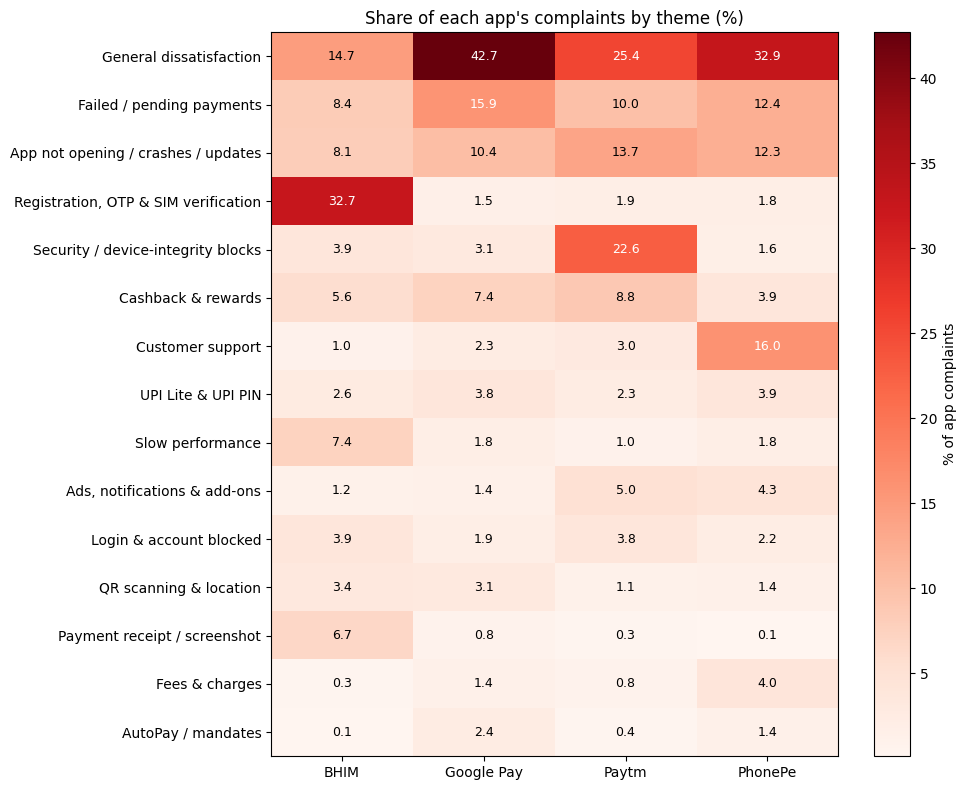

Saved complaints_with_themes.parquet and reports/theme_by_app.csv


In [ ]:
import matplotlib.pyplot as plt
apps = ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']

def named_shares(d):
    d = d[d.theme.isin(NAMED)]
    return pd.crosstab(d.theme, d.app, normalize='columns').mul(100)
core_only = named_shares(docs_df[docs_df.theme_method == 'topic model (core)'])
final = named_shares(docs_df)
print('Robustness: largest change in any theme share (percentage points), core-only vs final:',
      round(float((final - core_only.reindex_like(final)).abs().max().max()), 1))

absa = docs_df.groupby(['app', 'theme']).agg(
    complaints=('review_id', 'size'),
    avg_rating=('rating', 'mean'),
    pct_model_negative=('bert_label', lambda s: (s == 'negative').mean() * 100),
    pct_hidden_4_5_star=('rating', lambda s: (s >= 4).mean() * 100),
    avg_helpful_votes=('helpful_votes', 'mean')).round(2)
absa['share_of_app_pct'] = (absa.complaints / absa.groupby(level=0).complaints.transform('sum') * 100).round(1)
absa.to_csv(f'{BASE}/reports/theme_by_app.csv')
for a in apps:
    print(f'\n=== {a}: top themes ===')
    print(absa.loc[a].sort_values('share_of_app_pct', ascending=False).head(8).to_string())

hm = absa.share_of_app_pct.unstack(0).reindex(columns=apps).fillna(0)
hm = hm.loc[hm.mean(1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(hm.values, cmap='Reds', aspect='auto')
ax.set_xticks(range(len(apps))); ax.set_xticklabels(apps)
ax.set_yticks(range(len(hm))); ax.set_yticklabels(hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=9, color='white' if v > 15 else 'black')
ax.set_title("Share of each app's complaints by theme (%)")
plt.colorbar(im, ax=ax, label='% of app complaints'); plt.tight_layout()
plt.savefig(f'{BASE}/reports/figures/07_theme_heatmap.png', dpi=150); plt.show()

docs_df.to_parquet(f'{PROC}/complaints_with_themes.parquet', index=False)
print('Saved complaints_with_themes.parquet and reports/theme_by_app.csv')

In [ ]:
# (a) where does the change come from?
diff = (final - core_only.reindex_like(final)).round(1)
print(pd.concat({'core only': core_only.round(1), 'final': final.round(1), 'change': diff}, axis=1).to_string())

# (b) stricter threshold: preview only, nothing is overwritten
thr50 = np.percentile(own, 50)
assign50 = todo & (best_sim >= thr50)
print('\nStricter threshold:', round(float(thr50), 3), '| would reassign', assign50.sum(), 'instead of', assign.sum())
rng = np.random.default_rng(3)
for i in rng.choice(np.where(assign50)[0], 15, replace=False):
    print(f'  [{NAMED[best[i]]}]  {str(docs_df.review_text.iloc[i])[:130]}')

                                     core only                          final                          change                         
app                                       BHIM Google Pay Paytm PhonePe  BHIM Google Pay Paytm PhonePe   BHIM Google Pay Paytm PhonePe
theme                                                                                                                                 
Ads, notifications & add-ons               1.3        2.6   8.0     7.2   1.5        3.3   6.5     6.0    0.1        0.7  -1.5    -1.2
App not opening / crashes / updates        8.1       20.2  17.5    21.0  10.8       17.4  19.0    18.9    2.7       -2.8   1.4    -2.2
AutoPay / mandates                         0.1        5.4   0.6     2.8   0.1        3.6   0.4     1.9    0.0       -1.7  -0.1    -0.9
Cashback & rewards                         5.3       10.8  10.2     4.0   7.1       12.6  12.3     6.4    1.7        1.8   2.1     2.4
Customer support                           0.9        3

Phase 7c – LDA Comparison & Themes over Time

Cell L1: setup and quality measures

In [ ]:
!pip install -q bertopic
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 120)

BASE = '/content/drive/MyDrive/upi-complaint-analytics'
PROC = f'{BASE}/data/processed'
docs_df = pd.read_parquet(f'{PROC}/complaints_with_themes.parquet')
try:
    topic_model
except NameError:
    from bertopic import BERTopic
    topic_model = BERTopic.load(f'{PROC}/bertopic_model')

TOKEN = r'(?u)\b[a-z]{2,}\b'
cv_coh = CountVectorizer(token_pattern=TOKEN, binary=True)          # for coherence: every word, presence/absence
D = cv_coh.fit_transform(docs_df.text_full).tocsc()
vid = {w: i for i, w in enumerate(cv_coh.get_feature_names_out())}
N = D.shape[0]
dfc = np.asarray(D.sum(0)).ravel()

def npmi(words):
    ids = [vid[w] for w in words if w in vid]
    out = []
    for a in range(len(ids)):
        for b in range(a + 1, len(ids)):
            i, j = ids[a], ids[b]
            co = D[:, i].multiply(D[:, j]).sum()
            if co == 0:
                out.append(-1.0); continue
            p_ij, p_i, p_j = co / N, dfc[i] / N, dfc[j] / N
            out.append(np.log(p_ij / (p_i * p_j)) / -np.log(p_ij) if p_ij < 1 else 0.0)
    return np.mean(out) if out else np.nan

def score(name, topic_words):
    flat = [w for t in topic_words for w in t]
    return {'model': name, 'topics': len(topic_words),
            'coherence_npmi': round(float(np.nanmean([npmi(t) for t in topic_words])), 3),
            'diversity': round(len(set(flat)) / len(flat), 3)}

print(N, 'complaints loaded')

12202 complaints loaded


Cell L2: LDA vs BERTopic

In [ ]:
SAME_FILTER = dict(min_df=5, max_df=0.5, token_pattern=TOKEN)   # identical word filtering for both models

# BERTopic: same topics as before, re-described with single words and the same filter (assignments unchanged)
topic_model.update_topics(docs_df.text_full.tolist(), topics=docs_df.topic.tolist(),
                          vectorizer_model=CountVectorizer(**SAME_FILTER), top_n_words=10)
bt_words = [[w for w, _ in topic_model.get_topic(t)][:10] for t in sorted(set(docs_df.topic)) if t != -1]

cv_lda = CountVectorizer(**SAME_FILTER)
X_lda = cv_lda.fit_transform(docs_df.text_full)
v_lda = np.array(cv_lda.get_feature_names_out())
results, lda_words = [], {}
for k in [15, 40]:
    lda = LatentDirichletAllocation(n_components=k, learning_method='batch', max_iter=25,
                                    random_state=42, n_jobs=-1).fit(X_lda)
    lda_words[k] = [list(v_lda[np.argsort(c)[::-1][:10]]) for c in lda.components_]
    results.append(score(f'LDA (k={k})', lda_words[k]))
results.append(score('BERTopic (40 topics)', bt_words))

comp = pd.DataFrame(results)
comp.to_csv(f'{BASE}/reports/topic_model_comparison.csv', index=False)
print(comp.to_string(index=False))

print('\nLDA k=15, first 8 topics:')
for i, t in enumerate(lda_words[15][:8]):
    print(f'  LDA {i}:', ', '.join(t))
print('\nBERTopic, 8 of its topics:')
for t in [1, 5, 6, 7, 10, 22, 26, 27]:
    print(f'  BT {t}:', ', '.join(w for w, _ in topic_model.get_topic(t)[:10]))

2026-10-19 17:23:32,791 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


               model  topics  coherence_npmi  diversity
          LDA (k=15)      15           0.124      0.760
          LDA (k=40)      40           0.096      0.738
BERTopic (40 topics)      40          -0.362      0.708

LDA k=15, first 8 topics:
  LDA 0: open, slow, time, take, bad, much, experience, security, payment, lag
  LDA 1: time, try, unable, show, day, last, login, every, many, error
  LDA 2: useless, charge, aap, recharge, loan, money, use, platform, payment, fee
  LDA 3: problem, please, solve, delete, help, download, third, refer, sir, class
  LDA 4: use, upi, bad, people, no, one, ever, want, never, well
  LDA 5: account, money, bank, payment, upi, amount, receive, bad, send, show
  LDA 6: mobile, use, number, data, device, sim, show, phone, register, error
  LDA 7: otp, auto, enter, login, read, manually, option, work, able, fetch

BERTopic, 8 of its topics:
  BT 1: manually, read, reading, keyboard, manual, fill, registration, fetching, autoreade, autoread
  BT 5: e

Cell L3: themes over time and emerging problems

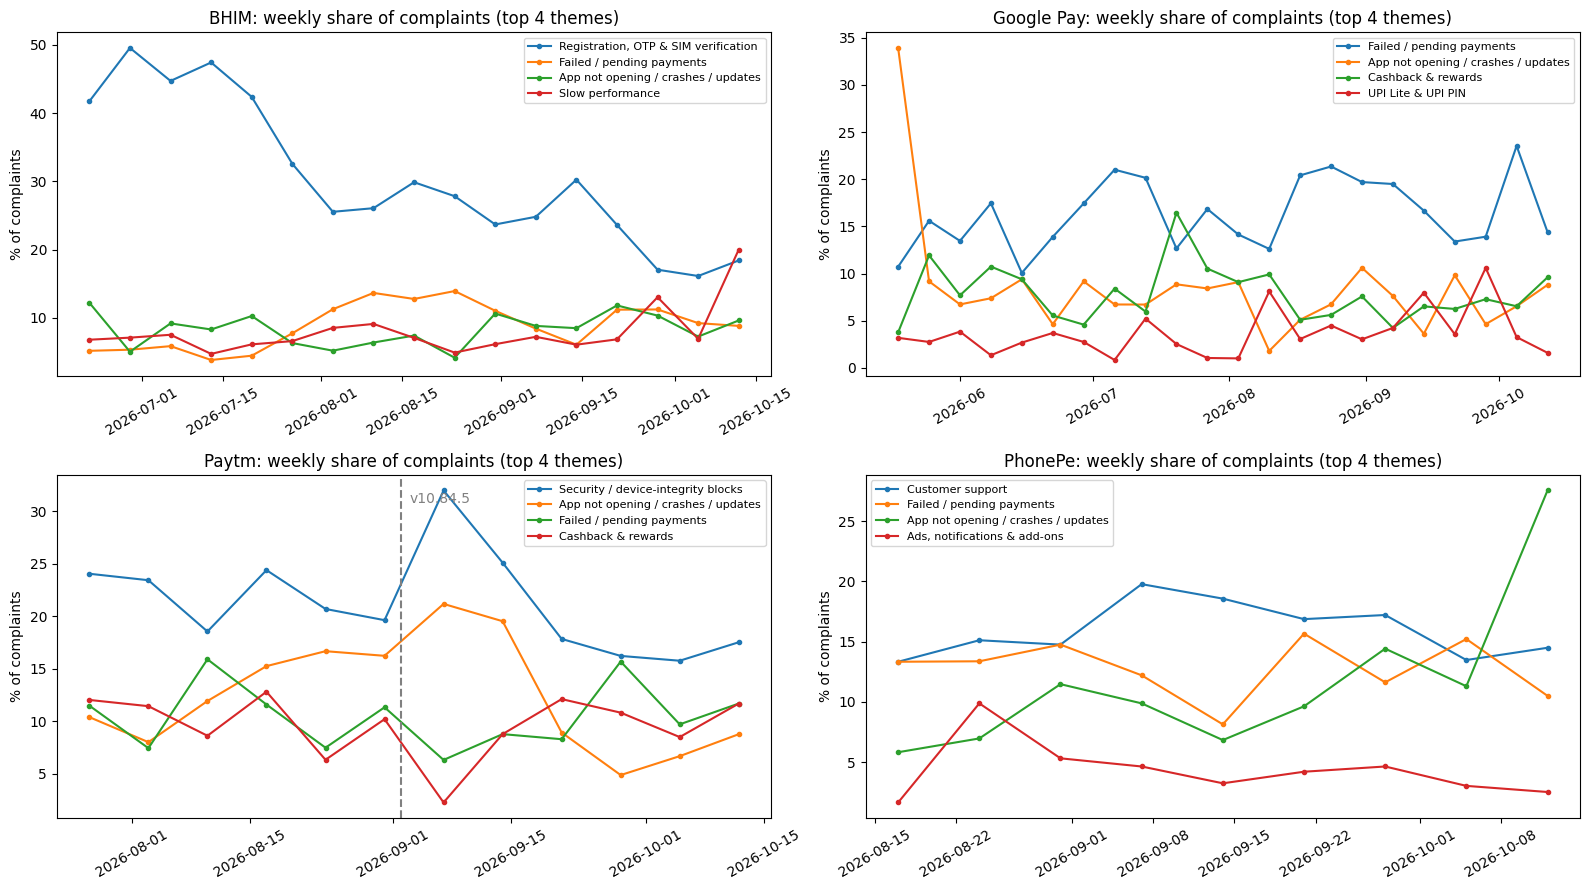

Rising themes (last 4 weeks vs earlier):
 period                                          earlier  last 4 weeks  change_pp  n_last_4_weeks
app        theme                                                                                
PhonePe    App not opening / crashes / updates      8.4          16.7        8.3           149.0
BHIM       QR scanning & location                   2.1           8.7        6.6            84.0
           Cashback & rewards                       4.4          10.6        6.2           103.0
Google Pay General dissatisfaction                 41.8          46.4        4.6           252.0
Paytm      General dissatisfaction                 24.4          28.4        3.9           184.0
BHIM       Slow performance                         6.7          10.0        3.3            97.0
Paytm      Login & account blocked                  3.0           5.9        2.8            38.0
           Cashback & rewards                       8.1          10.8        2.7     

In [ ]:
d = docs_df.copy()
d['week'] = d.review_date.dt.to_period('W').dt.start_time
NAMED = [t for t in d.theme.unique() if t != 'General dissatisfaction']
apps = ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, a in zip(axes.ravel(), apps):
    s = d[d.app == a]
    n_week = s.groupby('week').size()
    good_weeks = n_week[n_week >= 30].index                     # skip thin weeks
    p = (s.groupby(['week', 'theme']).size().unstack(fill_value=0)
          .div(n_week, axis=0).mul(100).loc[good_weeks])
    for th in s[s.theme.isin(NAMED)].theme.value_counts().index[:4]:
        ax.plot(p.index, p[th], marker='o', ms=3, label=th)
    if a == 'Paytm':
        ax.axvline(pd.Timestamp('2026-09-02'), ls='--', color='grey')
        ax.text(pd.Timestamp('2026-09-03'), ax.get_ylim()[1] * 0.92, 'v10.84.5', color='grey')
    ax.set_title(f'{a}: weekly share of complaints (top 4 themes)')
    ax.set_ylabel('% of complaints'); ax.legend(fontsize=8); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig(f'{BASE}/reports/figures/08_themes_over_time.png', dpi=150); plt.show()

cut = d.groupby('app').review_date.transform('max') - pd.Timedelta(days=28)
d['period'] = np.where(d.review_date > cut, 'last 4 weeks', 'earlier')
cnt = d.groupby(['app', 'period', 'theme']).size()
sh = (cnt / cnt.groupby(level=[0, 1]).transform('sum') * 100).unstack('period').fillna(0)
sh['change_pp'] = sh['last 4 weeks'] - sh['earlier']
sh['n_last_4_weeks'] = cnt.unstack('period').fillna(0)['last 4 weeks']
sh = sh[sh.n_last_4_weeks >= 20].round(1)
print('Rising themes (last 4 weeks vs earlier):\n', sh.sort_values('change_pp', ascending=False).head(8).to_string())
print('\nFalling themes:\n', sh.sort_values('change_pp').head(6).to_string())

Cell L4: the two events from EDA

In [ ]:
SEC = 'Security / device-integrity blocks'
p = d[d.app == 'Paytm']
pw = p.groupby('week').agg(complaints=('review_id', 'size'), security=('theme', lambda s: (s == SEC).sum()))
pw['security_pct'] = (pw.security / pw.complaints * 100).round(1)
print('Paytm by week:\n', pw.to_string())
print('\nPaytm by app version (50+ complaints):\n',
      p.groupby('app_version').agg(complaints=('review_id', 'size'),
                                   security_pct=('theme', lambda s: round((s == SEC).mean() * 100, 1)))
       .query('complaints >= 50').to_string())

g = d[(d.app == 'Google Pay') & (d.review_date < '2026-05-21')]
print(f'\nGoogle Pay 18-20 May: {len(g)} long complaints\n', g.theme.value_counts().head(6).to_string())
for t in g.sort_values('helpful_votes', ascending=False).review_text.head(8):
    print('  •', str(t)[:160])

Paytm by week:
             complaints  security  security_pct
week                                          
2026-07-20          17         3          17.6
2026-07-27         183        44          24.0
2026-08-03         175        41          23.4
2026-08-10         151        28          18.5
2026-08-17         164        40          24.4
2026-08-24         174        36          20.7
2026-08-31         265        52          19.6
2026-09-07         444       142          32.0
2026-09-14         251        63          25.1
2026-09-21         157        28          17.8
2026-09-28         185        30          16.2
2026-10-05         165        26          15.8
2026-10-12         137        24          17.5

Paytm by app version (50+ complaints):
              complaints  security_pct
app_version                          
10.83.10             96          24.0
10.83.12            633          19.4
10.83.5              55          23.6
10.84.5             406          35.0
10.85.3   

### Cell L5: corrected LDA vs BERTopic comparison
BERTopic keywords are recomputed with c-TF-IDF on the same document-level vocabulary as LDA, so the coherence scores are directly comparable.

In [4]:
# Cell L5: CORRECTED comparison of LDA vs BERTopic (self-contained, replaces the BERTopic row from L2)
# Why: in L2, BERTopic's word filter was applied to whole-topic documents, which removed common words
# and kept rare typos. Here BERTopic's topic words are recomputed with its own c-TF-IDF formula on the
# SAME document-level vocabulary as LDA. Topic assignments are unchanged.
from google.colab import drive
drive.mount('/content/drive')
import numpy as np, pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
pd.set_option('display.width', 220)

BASE = '/content/drive/MyDrive/upi-complaint-analytics'
PROC = f'{BASE}/data/processed'
docs_df = pd.read_parquet(f'{PROC}/complaints_with_themes.parquet')

TOKEN = r'(?u)\b[a-z]{2,}\b'
cv_coh = CountVectorizer(token_pattern=TOKEN, binary=True)        # coherence: word presence per review
D = cv_coh.fit_transform(docs_df.text_full).tocsc()
vid = {w: i for i, w in enumerate(cv_coh.get_feature_names_out())}
N = D.shape[0]
dfc = np.asarray(D.sum(0)).ravel()

def npmi(words):
    ids = [vid[w] for w in words if w in vid]
    out = []
    for a in range(len(ids)):
        for b in range(a + 1, len(ids)):
            i, j = ids[a], ids[b]
            co = D[:, i].multiply(D[:, j]).sum()
            if co == 0:
                out.append(-1.0)
                continue
            p_ij, p_i, p_j = co / N, dfc[i] / N, dfc[j] / N
            out.append(np.log(p_ij / (p_i * p_j)) / -np.log(p_ij) if p_ij < 1 else 0.0)
    return np.mean(out) if out else np.nan

def score(name, topic_words):
    flat = [w for t in topic_words for w in t]
    return {'model': name, 'topics': len(topic_words),
            'coherence_npmi': round(float(np.nanmean([npmi(t) for t in topic_words])), 3),
            'diversity': round(len(set(flat)) / len(flat), 3)}

SAME_FILTER = dict(min_df=5, max_df=0.5, token_pattern=TOKEN)    # identical vocabulary for both models
cv_lda = CountVectorizer(**SAME_FILTER)
X_lda = cv_lda.fit_transform(docs_df.text_full)
v_lda = np.array(cv_lda.get_feature_names_out())

results, lda_words = [], {}
for k in [15, 40]:
    lda = LatentDirichletAllocation(n_components=k, learning_method='batch', max_iter=25,
                                    random_state=42, n_jobs=-1).fit(X_lda)
    lda_words[k] = [list(v_lda[np.argsort(c)[::-1][:10]]) for c in lda.components_]
    results.append(score(f'LDA (k={k})', lda_words[k]))

# BERTopic: c-TF-IDF (Grootendorst 2022) on the same vocabulary, using the saved topic of each review
topics_arr = docs_df.topic.values
classes = sorted(t for t in set(topics_arr) if t != -1)
tf = np.vstack([np.asarray(X_lda[topics_arr == t].sum(0)).ravel() for t in classes])
A = tf.sum(1).mean()
f = tf.sum(0).astype(float)
f[f == 0] = 1
ctfidf = (tf / tf.sum(1, keepdims=True)) * np.log(1 + A / f)
bt_fair = [list(v_lda[np.argsort(r)[::-1][:10]]) for r in ctfidf]
results.append(score('BERTopic (40 topics)', bt_fair))

comp = pd.DataFrame(results)
comp.to_csv(f'{BASE}/reports/topic_model_comparison.csv', index=False)
print(comp.to_string(index=False))

print('\nBERTopic topics (corrected words):')
for t, w in zip(classes, bt_fair):
    print(f'  BT {t}:', ', '.join(w))
print('\nLDA k=15 topics:')
for i, w in enumerate(lda_words[15]):
    print(f'  LDA {i}:', ', '.join(w))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
               model  topics  coherence_npmi  diversity
          LDA (k=15)      15           0.124      0.760
          LDA (k=40)      40           0.096      0.738
BERTopic (40 topics)      40           0.168      0.545

BERTopic topics (corrected words):
  BT 0: useless, karne, hota, aap, bar, liye, kya, karna, din, jata
  BT 1: otp, auto, manually, read, enter, reading, login, fetch, type, option
  BT 2: google, account, money, payment, transaction, bank, reward, issue, use, work
  BT 3: payment, money, transaction, account, amount, history, receive, debit, show, deduct
  BT 4: open, work, update, crash, close, device, environment, properly, issue, problem
  BT 5: device, alert, security, please, open, environment, support, work, issue, contact
  BT 6: screenshot, share, payment, receipt, transaction, take, sharing, screen, whatsapp, work
  BT 7: mobile

## Business impact (Phase 8a)
Which complaint themes cost the most stars, and what would fixing them be worth?

In [9]:
# ===== Phase 8a – Business impact: rating drivers, priority matrix, "what if we fixed it" =====
# Cell M1: tag EVERY review with the themes it mentions (keyword rules built from the BERTopic theme words).
# Why not reuse the BERTopic themes directly? They exist only for complaints, which are low-rated by
# definition, so regressing the rating on them would be circular. Mentions work for happy and unhappy reviews.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf, warnings
warnings.filterwarnings('ignore', message='This pattern is interpreted as a regular expression')
pd.set_option('display.width', 220)

BASE = '/content/drive/MyDrive/upi-complaint-analytics'
PROC = f'{BASE}/data/processed'
rev = pd.read_parquet(f'{PROC}/reviews_with_sentiment.parquet')
themes_cmp = pd.read_parquet(f'{PROC}/complaints_with_themes.parquet')[['review_id', 'theme']]

THEME_RULES = {
    'otp':      ('Registration, OTP & SIM verification', r"\botps?\b|auto ?read|auto ?fetch|\bsms\b|verif|onboard|regist|\bsim\b|mobile data"),
    'security': ('Security / device-integrity blocks', r"security (alert|check|reason|issue|warning)|device environment|\benvironment\b|\broot(ed)?\b|malicious|suspicious app|developer option|usb debugging|accessibility|integrity|download(ed)? (it )?from (the )?(google )?play|(installed|install|update[d]?) from (the )?play ?store|verifying (the |your )?device|too many (login )?attempts"),
    'login':    ('Login & account blocked', r"\blog ?in\b|account (is |was |got |has been )?(blocked|suspended|locked|frozen|closed)|\bsuspend"),
    'crash':    ('App not opening / crashes / updates', r"not open|not working|not work\b|crash|clos(e|es|ed|ing) (automatically|itself|suddenly)|getting closed|gets closed|stops? working|stopped working|not responding|\bhang|freez|glitch|disappear|after (the |this |latest )?update|new update|not updat"),
    'slow':     ('Slow performance', r"\bslow|\blag|takes? (too )?(much|long) time|too much time|loading"),
    'payment':  ('Failed / pending payments', r"fail|pending|deduct|debited|not (received|credited|reflect)|(money|payment|amount|transaction) (is |was |got )?(stuck|cut)|refund|(not able|unable) to (pay|send|transfer|recharge)|(payment|transaction|transfer)s? (issue|problem|error|not)|insufficient|wrong balance|not paid"),
    'support':  ('Customer support', r"customer (care|support|service)|helpline|toll ?free|no response|no reply|support team|\bchat\b|executive|\bcalls?\b|complain|ticket|e-?mail|\bmail\b|contact|help ?desk"),
    'cashback': ('Cashback & rewards', r"cash ?back|reward|scratch ?card|coupon|voucher|\boffers?\b"),
    'fees':     ('Fees & charges', r"platform fee|convenience fee|extra charge|\bcharges?\b|\bfees?\b|surcharge|\bgst\b"),
    'upilite':  ('UPI Lite & UPI PIN', r"upi lite|\blite\b|upi pin|\bpin\b"),
    'autopay':  ('AutoPay / mandates', r"auto ?pay|mandate|subscription"),
    'qr':       ('QR scanning & location', r"\bscan|\bqr\b|camera|location"),
    'receipt':  ('Payment receipt / screenshot', r"screenshot|screen shot|receipt|transaction id|\bproof\b"),
    'ads':      ('Ads, notifications & add-ons', r"\bads?\b|advertis|notification|promotion|\bspam|\bgold\b|\bloans?\b|insurance"),
}
for code, (name, pat) in THEME_RULES.items():
    rev['m_' + code] = rev.text_light.str.contains(pat, regex=True).astype(int)
MCOLS = ['m_' + c for c in THEME_RULES]
NAME = {'m_' + c: v[0] for c, v in THEME_RULES.items()}
print('Reviews mentioning at least one theme:', round(rev[MCOLS].max(1).mean() * 100, 1), '%')

# Validation: share of the complaints BERTopic placed in a theme that the theme's keywords also catch
chk = themes_cmp.merge(rev[['review_id'] + MCOLS], on='review_id')
val = pd.DataFrame({NAME[c]: {'bertopic_complaints': int((chk.theme == NAME[c]).sum()),
                              'keyword_coverage_%': round(chk.loc[chk.theme == NAME[c], c].mean() * 100, 1),
                              'mention_rate_all_reviews_%': round(rev[c].mean() * 100, 2)} for c in MCOLS}).T
print(val.sort_values('bertopic_complaints', ascending=False).to_string())

Reviews mentioning at least one theme: 15.3 %
                                      bertopic_complaints  keyword_coverage_%  mention_rate_all_reviews_%
Registration, OTP & SIM verification               1761.0                84.8                        2.67
Failed / pending payments                          1353.0                32.8                        1.92
App not opening / crashes / updates                1274.0                53.6                        3.99
Security / device-integrity blocks                  868.0                27.0                        0.60
Cashback & rewards                                  784.0                87.5                        2.52
Customer support                                    494.0                51.8                        1.91
Slow performance                                    477.0                76.5                        1.86
Login & account blocked                             384.0                56.2                        1.39


Reviews: 85150 | R-squared: 0.382 | log_words effect: -0.525
                               theme  stars_effect  ci_low  ci_high  p_value  mention_rate_%
                  AutoPay / mandates        -1.220  -1.402   -1.037   0.0000            0.31
 App not opening / crashes / updates        -1.101  -1.160   -1.042   0.0000            3.99
  Security / device-integrity blocks        -1.098  -1.235   -0.961   0.0000            0.60
                      Fees & charges        -0.860  -1.025   -0.695   0.0000            0.52
Registration, OTP & SIM verification        -0.844  -0.917   -0.770   0.0000            2.67
           Failed / pending payments        -0.760  -0.842   -0.677   0.0000            1.92
             Login & account blocked        -0.738  -0.835   -0.641   0.0000            1.39
                    Customer support        -0.712  -0.795   -0.629   0.0000            1.91
        Ads, notifications & add-ons        -0.681  -0.794   -0.568   0.0000            1.07
         

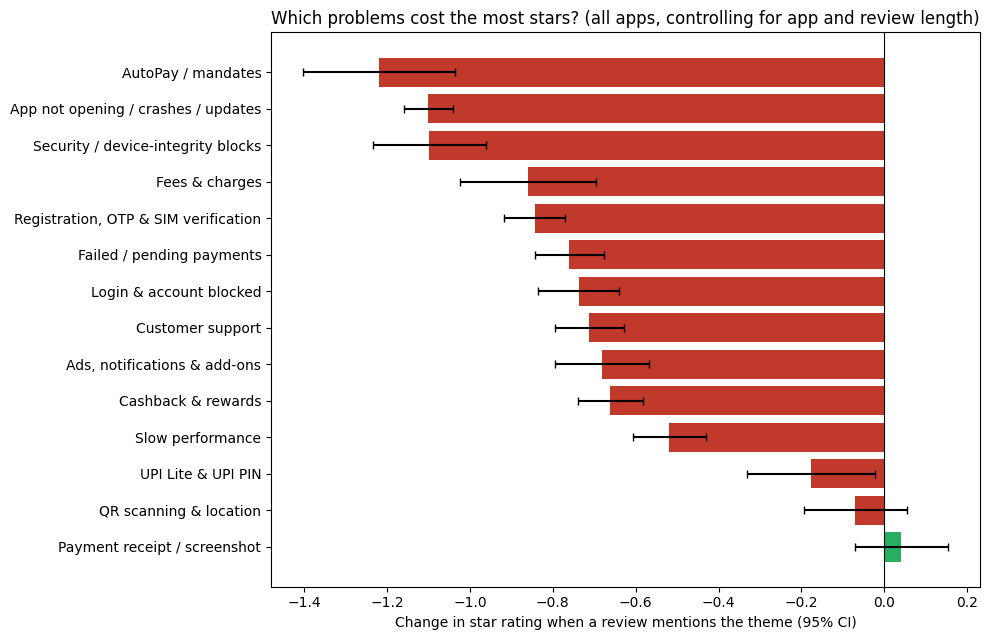

In [10]:
# Cell M2: rating driver model (all apps): how many stars is a review worth less when it mentions a theme?
# OLS with robust (HC3) standard errors, controlling for the app and for review length.
rev['log_words'] = np.log1p(rev.n_words)
ols = smf.ols('rating ~ ' + ' + '.join(MCOLS) + ' + log_words + C(app)', data=rev).fit(cov_type='HC3')
ci = ols.conf_int()
coef = pd.DataFrame({'theme': [NAME[c] for c in MCOLS],
                     'stars_effect': ols.params[MCOLS].values.round(3),
                     'ci_low': ci.loc[MCOLS, 0].values.round(3),
                     'ci_high': ci.loc[MCOLS, 1].values.round(3),
                     'p_value': ols.pvalues[MCOLS].values.round(4),
                     'mention_rate_%': (rev[MCOLS].mean().values * 100).round(2)}).sort_values('stars_effect')
print('Reviews:', int(ols.nobs), '| R-squared:', round(ols.rsquared, 3),
      '| log_words effect:', round(ols.params['log_words'], 3))
print(coef.to_string(index=False))
coef.to_csv(f'{BASE}/reports/rating_drivers_all_apps.csv', index=False)

c2 = coef.sort_values('stars_effect', ascending=False)
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(c2.theme, c2.stars_effect, xerr=[c2.stars_effect - c2.ci_low, c2.ci_high - c2.stars_effect],
        color=['#C0392B' if v < 0 else '#27AE60' for v in c2.stars_effect], capsize=3)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Change in star rating when a review mentions the theme (95% CI)')
ax.set_title('Which problems cost the most stars? (all apps, controlling for app and review length)')
plt.tight_layout(); plt.savefig(f'{BASE}/reports/figures/09_rating_drivers.png', dpi=150); plt.show()


=== BHIM: current average 2.675 stars | top fixes by potential rating gain ===
                               theme  reviews_mentioning  prevalence_%  stars_effect  p_value  gain_if_fixed  gain_if_halved
Registration, OTP & SIM verification                1929         19.45        -0.986   0.0000          0.182           0.091
 App not opening / crashes / updates                1532         15.45        -0.549   0.0000          0.079           0.039
                    Slow performance                1128         11.38        -0.420   0.0000          0.044           0.022
             Login & account blocked                 793          8.00        -0.509   0.0000          0.038           0.019
           Failed / pending payments                 617          6.22        -0.597   0.0000          0.034           0.017
                  Cashback & rewards                 718          7.24        -0.257   0.0002          0.014           0.007

=== Google Pay: current average 3.989 stars 

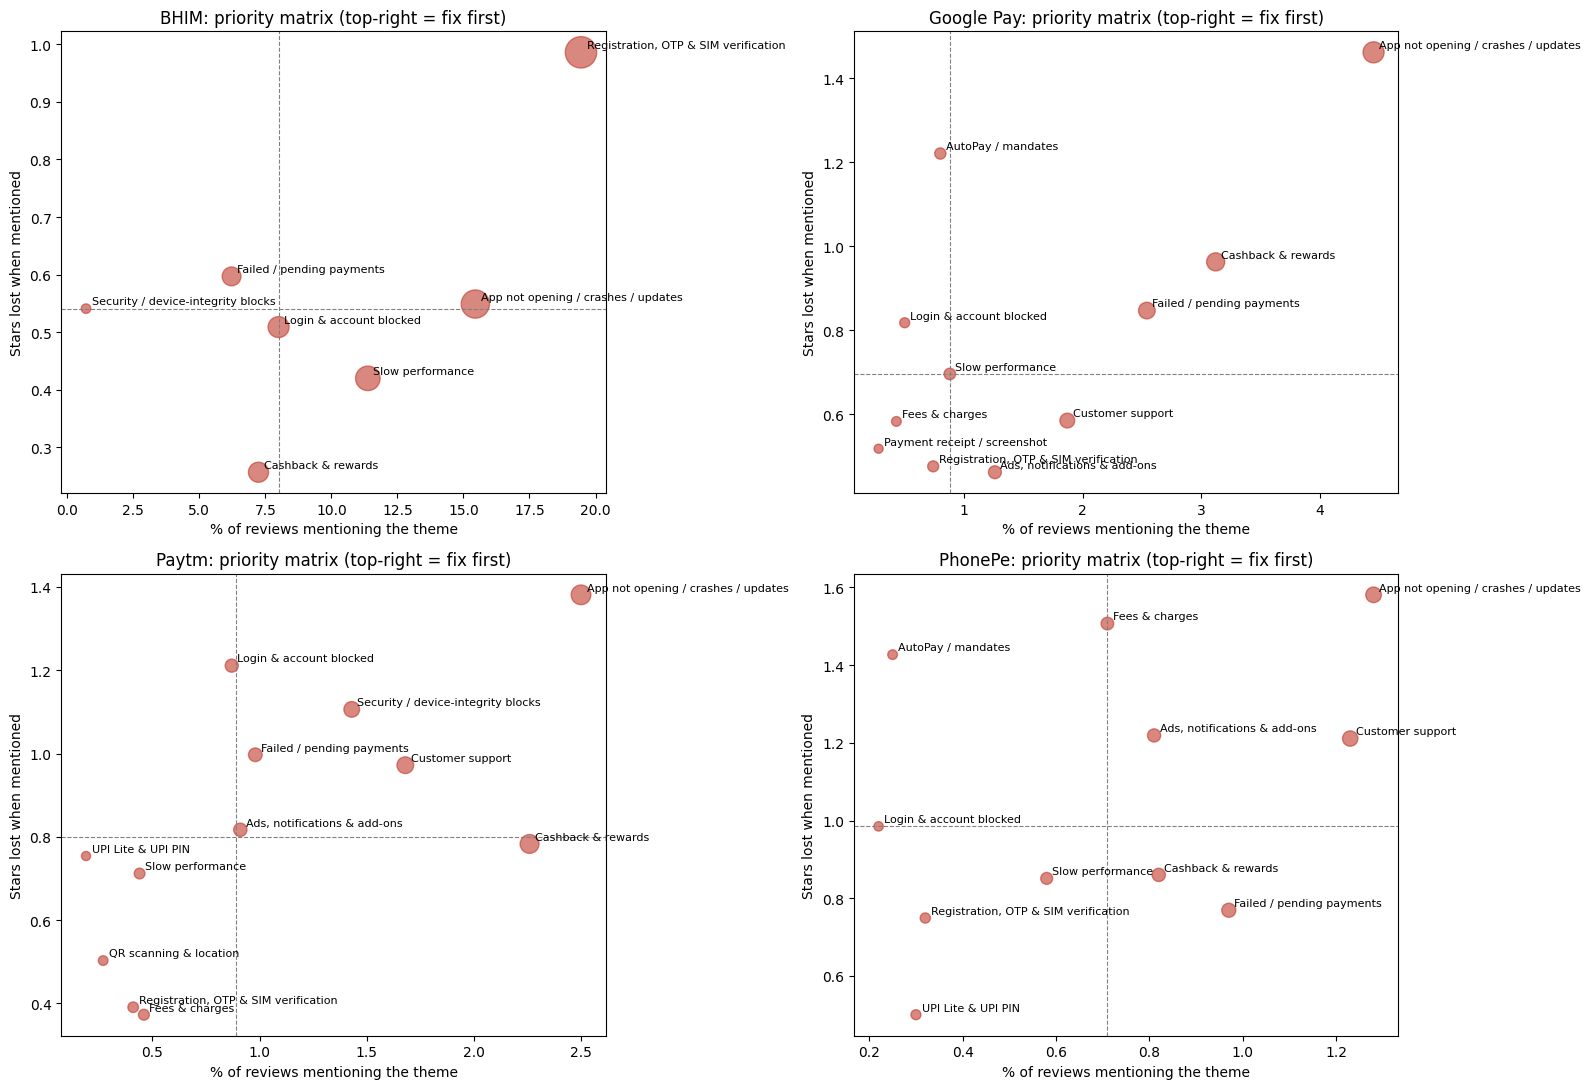

Saved priority_matrix.csv, rating_drivers_all_apps.csv, theme_mentions.parquet and 2 figures


In [11]:
# Cell M3: per-app priority matrix and "what if we fixed it" simulation
# Per app: frequency (% of reviews mentioning a theme) x severity (stars lost, from a per-app regression).
# Simulation: reviews mentioning a significant theme get its star penalty back (capped at 5 stars).
apps = ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']
rows = []
for a in apps:
    d = rev[rev.app == a]
    m = smf.ols('rating ~ ' + ' + '.join(MCOLS) + ' + log_words', data=d).fit(cov_type='HC3')
    base = d.rating.mean()
    for c in MCOLS:
        eff, p, n = m.params[c], m.pvalues[c], int(d[c].sum())
        penalty = -eff if (eff < 0 and p < 0.05) else 0.0
        fixed = np.where(d[c] == 1, np.minimum(5, d.rating + penalty), d.rating).mean()
        rows.append({'app': a, 'theme': NAME[c], 'reviews_mentioning': n, 'prevalence_%': round(n / len(d) * 100, 2),
                     'stars_effect': round(eff, 3), 'p_value': round(p, 4), 'current_avg': round(base, 3),
                     'gain_if_fixed': round(fixed - base, 3), 'gain_if_halved': round((fixed - base) / 2, 3)})
pri = pd.DataFrame(rows)
pri.to_csv(f'{BASE}/reports/priority_matrix.csv', index=False)
for a in apps:
    t = pri[(pri.app == a) & (pri.reviews_mentioning >= 30)].sort_values('gain_if_fixed', ascending=False)
    print(f'\n=== {a}: current average {t.current_avg.iloc[0]} stars | top fixes by potential rating gain ===')
    print(t[['theme', 'reviews_mentioning', 'prevalence_%', 'stars_effect', 'p_value', 'gain_if_fixed', 'gain_if_halved']]
          .head(6).to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, a in zip(axes.ravel(), apps):
    t = pri[(pri.app == a) & (pri.reviews_mentioning >= 30) & (pri.stars_effect < 0) & (pri.p_value < 0.05)].copy()
    t['penalty'] = -t.stars_effect
    ax.scatter(t['prevalence_%'], t.penalty, s=t.reviews_mentioning.clip(upper=3000) / 4 + 30, alpha=0.6, color='#C0392B')
    for _, r in t.iterrows():
        ax.annotate(r.theme, (r['prevalence_%'], r.penalty), fontsize=8, xytext=(4, 3), textcoords='offset points')
    if len(t):
        ax.axvline(t['prevalence_%'].median(), ls='--', c='grey', lw=0.8)
        ax.axhline(t.penalty.median(), ls='--', c='grey', lw=0.8)
    ax.set_title(f'{a}: priority matrix (top-right = fix first)')
    ax.set_xlabel('% of reviews mentioning the theme'); ax.set_ylabel('Stars lost when mentioned')
plt.tight_layout(); plt.savefig(f'{BASE}/reports/figures/10_priority_matrix.png', dpi=150); plt.show()
rev[['review_id'] + MCOLS].to_parquet(f'{PROC}/theme_mentions.parquet', index=False)
print('Saved priority_matrix.csv, rating_drivers_all_apps.csv, theme_mentions.parquet and 2 figures')

## Release events and company replies (Phase 8b)

In [12]:
# ===== Phase 8b – Version event study, release monitor, customer replies =====
# Cell V1: did Paytm version 10.84.5 really change ratings and security-block complaints? (statistical tests)
from scipy import stats
apps = ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']
TARGET = '10.84.5'
p = rev[(rev.app == 'Paytm') & rev.app_version.notna()].copy()
first_seen = p.groupby('app_version').review_date.min()
p['group'] = np.where(p.app_version == TARGET, TARGET,
                      np.where(p.app_version.map(first_seen) < first_seen[TARGET], 'earlier versions', 'later versions'))
summ = p.groupby('group').agg(reviews=('review_id', 'size'), avg_rating=('rating', 'mean'),
                              pct_1_star=('rating', lambda s: (s == 1).mean() * 100),
                              pct_security_mention=('m_security', lambda s: s.mean() * 100),
                              pct_crash_mention=('m_crash', lambda s: s.mean() * 100),
                              pct_login_mention=('m_login', lambda s: s.mean() * 100)).round(2)
print(summ.loc[['earlier versions', TARGET, 'later versions']].to_string())

def compare(a, b):
    A, B = p[p.group == a], p[p.group == b]
    mw = stats.mannwhitneyu(A.rating, B.rating).pvalue
    sec = stats.chi2_contingency([[A.m_security.sum(), len(A) - A.m_security.sum()],
                                  [B.m_security.sum(), len(B) - B.m_security.sum()]])[1]
    one = stats.chi2_contingency([[(A.rating == 1).sum(), (A.rating != 1).sum()],
                                  [(B.rating == 1).sum(), (B.rating != 1).sum()]])[1]
    print(f'{a:>16} vs {b:<16} | ratings (Mann-Whitney) p = {mw:.1e} | security mentions (chi-square) p = {sec:.1e} | 1-star share p = {one:.1e}')
print()
compare('earlier versions', TARGET)
compare(TARGET, 'later versions')

# Same test on the BERTopic themes of Paytm's long complaints
pc = p.merge(themes_cmp, on='review_id')
pc['is_security'] = pc.theme == 'Security / device-integrity blocks'
print('\nSecurity-block share of Paytm complaints:', pc.groupby('group').is_security.mean().mul(100).round(1).to_dict())
A, B = pc[pc.group == TARGET], pc[pc.group != TARGET]
print('10.84.5 vs all other versions (chi-square) p =',
      f"{stats.chi2_contingency([[A.is_security.sum(), len(A) - A.is_security.sum()], [B.is_security.sum(), len(B) - B.is_security.sum()]])[1]:.1e}")

                  reviews  avg_rating  pct_1_star  pct_security_mention  pct_crash_mention  pct_login_mention
group                                                                                                        
earlier versions    14264        4.50        9.22                  1.49               1.89               0.61
10.84.5              2486        4.11       17.58                  2.90               9.41               1.21
later versions       6983        4.63        6.69                  0.47               1.06               1.03

earlier versions vs 10.84.5          | ratings (Mann-Whitney) p = 9.5e-43 | security mentions (chi-square) p = 7.8e-07 | 1-star share p = 4.9e-36
         10.84.5 vs later versions   | ratings (Mann-Whitney) p = 6.4e-72 | security mentions (chi-square) p = 1.1e-22 | 1-star share p = 2.0e-56

Security-block share of Paytm complaints: {'10.84.5': 35.0, 'earlier versions': 21.3, 'later versions': 17.7}
10.84.5 vs all other versions (chi-square) p =

In [13]:
# Cell V2: release monitor – which versions (300+ reviews) were rated significantly worse than the rest of the same app?
# Mann-Whitney test per version, Bonferroni-corrected because many versions are tested at once.
rows = []
for a in apps:
    d = rev[(rev.app == a) & rev.app_version.notna()]
    vc = d.app_version.value_counts()
    for v in vc[vc >= 300].index:
        A, B = d[d.app_version == v], d[d.app_version != v]
        rising = (A[MCOLS].mean() - B[MCOLS].mean()).sort_values(ascending=False)
        rows.append({'app': a, 'version': v, 'first_seen': A.review_date.min().date(), 'reviews': len(A),
                     'avg_rating': round(A.rating.mean(), 2), 'rest_of_app': round(B.rating.mean(), 2),
                     'diff': round(A.rating.mean() - B.rating.mean(), 2),
                     'p_value': stats.mannwhitneyu(A.rating, B.rating).pvalue,
                     'mentions_rising_most': ', '.join(f'{NAME[c]} +{rising[c] * 100:.1f}pp' for c in rising.index[:2] if rising[c] > 0)})
mon = pd.DataFrame(rows)
mon['significant'] = mon.p_value < 0.05 / len(mon)
mon.to_csv(f'{BASE}/reports/release_monitor.csv', index=False)
pd.set_option('display.max_colwidth', 90)
print(len(mon), 'versions tested | Bonferroni threshold p <', round(0.05 / len(mon), 5))
print(mon.sort_values('diff').head(8).assign(p_value=lambda x: x.p_value.map(lambda v: f'{v:.1e}')).to_string(index=False))

38 versions tested | Bonferroni threshold p < 0.00132
       app                             version first_seen  reviews  avg_rating  rest_of_app  diff p_value                                                                  mentions_rising_most  significant
     Paytm                             10.84.5 2026-09-02     2486        4.11         4.54 -0.43 1.4e-59 App not opening / crashes / updates +7.8pp, Security / device-integrity blocks +1.7pp         True
Google Pay 331.1.2 (arm64-v8a_release_flutter) 2026-05-18     1097        3.60         4.02 -0.42 6.2e-15                  App not opening / crashes / updates +14.6pp, Slow performance +1.3pp         True
Google Pay 351.1.1 (arm64-v8a_release_flutter) 2026-09-29      444        3.73         4.00 -0.27 8.6e-04                                    Customer support +1.7pp, UPI Lite & UPI PIN +1.6pp         True
      BHIM                              4.0.24 2026-06-22     1707        2.52         2.78 -0.26 3.2e-08          Registratio

In [14]:
# Cell R1: customer replies – do unhappy users get a real answer, and how fast?
# A reply text sent 20+ times is counted as a template.
r = rev.copy()
r['replied'] = r.company_reply.notna()
r['reply_hours'] = (pd.to_datetime(r.reply_date) - pd.to_datetime(r.review_date)).dt.total_seconds() / 3600
r['template'] = r.company_reply.map(r.company_reply.value_counts()).fillna(0) >= 20
neg, pos = r[r.rating <= 2], r[r.rating == 5]
replies = pd.DataFrame({
    'reply_rate_all_%': r.groupby('app').replied.mean() * 100,
    'reply_rate_1_2_star_%': neg.groupby('app').replied.mean() * 100,
    'reply_rate_5_star_%': pos.groupby('app').replied.mean() * 100,
    'median_hours_1_2_star': neg[neg.replied].groupby('app').reply_hours.median(),
    'template_share_1_2_star_%': neg[neg.replied].groupby('app').template.mean() * 100,
    'template_share_5_star_%': pos[pos.replied].groupby('app').template.mean() * 100}).round(1)
replies.to_csv(f'{BASE}/reports/reply_analysis.csv')
print(replies.to_string())

# Which complaint themes do other users agree with most? (total and median helpful votes, not the skewed mean)
hv = themes_cmp.merge(rev[['review_id', 'app', 'helpful_votes']], on='review_id')
hv = hv[hv.theme != 'General dissatisfaction'].groupby(['app', 'theme']).helpful_votes.agg(
    complaints='size', total_votes='sum', median_votes='median')
for a in apps:
    print(f'\n{a}: themes with most helpful votes')
    print(hv.loc[a].sort_values('total_votes', ascending=False).head(4).to_string())

            reply_rate_all_%  reply_rate_1_2_star_%  reply_rate_5_star_%  median_hours_1_2_star  template_share_1_2_star_%  template_share_5_star_%
app                                                                                                                                                
BHIM                    96.8                   98.4                 93.8                   45.7                       95.9                     96.1
Google Pay              11.4                   44.1                  0.3                    0.3                        6.5                      2.5
Paytm                   96.2                   94.8                 96.5                    0.4                        8.5                     86.9
PhonePe                 25.8                   74.6                 16.9                    1.5                        0.0                     98.5

BHIM: themes with most helpful votes
                                      complaints  total_votes  median_vote

### Robustness check

In [15]:
# Cell C1: robustness check – does the "crashes" result survive without the vague phrase "not working"?
strict = r"not open|crash|clos(e|es|ed|ing) (automatically|itself|suddenly)|getting closed|gets closed|stopped working|not responding|\bhang|freez|glitch|disappear|after (the |this |latest )?update|new update|not updat"
rev['m_crash_strict'] = rev.text_light.str.contains(strict, regex=True).astype(int)
cols2 = [c for c in MCOLS if c != 'm_crash'] + ['m_crash_strict']
o2 = smf.ols('rating ~ ' + ' + '.join(cols2) + ' + log_words + C(app)', data=rev).fit(cov_type='HC3')
print('All apps | broad definition : effect', round(ols.params['m_crash'], 3), '| mentioned in', round(rev.m_crash.mean() * 100, 2), '% of reviews')
print('All apps | strict definition: effect', round(o2.params['m_crash_strict'], 3), '| mentioned in', round(rev.m_crash_strict.mean() * 100, 2), '% of reviews')
for a in apps:
    d = rev[rev.app == a]
    m = smf.ols('rating ~ ' + ' + '.join(cols2) + ' + log_words', data=d).fit(cov_type='HC3')
    eff, pv = m.params['m_crash_strict'], m.pvalues['m_crash_strict']
    pen = -eff if (eff < 0 and pv < 0.05) else 0
    gain = np.where(d.m_crash_strict == 1, np.minimum(5, d.rating + pen), d.rating).mean() - d.rating.mean()
    old = pri[(pri.app == a) & (pri.theme == 'App not opening / crashes / updates')].gain_if_fixed.iloc[0]
    print(f'{a:<11} strict: effect {eff:.3f} | mentioned {d.m_crash_strict.mean() * 100:.2f}% | gain if fixed {gain:.3f} (broad: {old:.3f})')

All apps | broad definition : effect -1.101 | mentioned in 3.99 % of reviews
All apps | strict definition: effect -0.909 | mentioned in 1.86 % of reviews
BHIM        strict: effect -0.384 | mentioned 6.95% | gain if fixed 0.024 (broad: 0.079)
Google Pay  strict: effect -1.248 | mentioned 2.00% | gain if fixed 0.022 (broad: 0.057)
Paytm       strict: effect -1.112 | mentioned 1.27% | gain if fixed 0.012 (broad: 0.028)
PhonePe     strict: effect -1.614 | mentioned 0.61% | gain if fixed 0.009 (broad: 0.017)


## Final charts (Phase 9a)

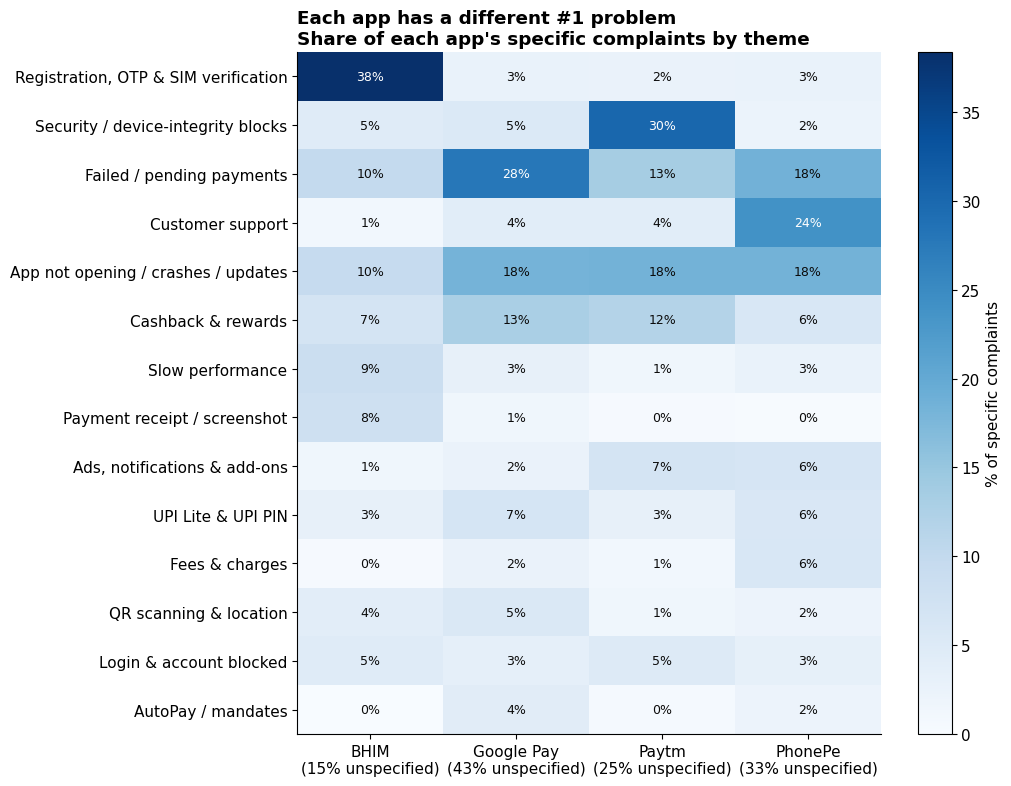

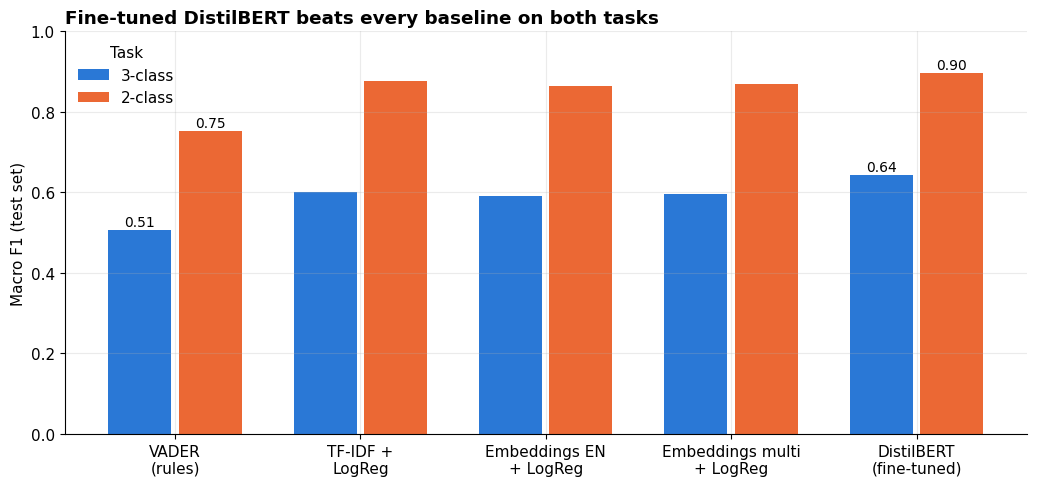

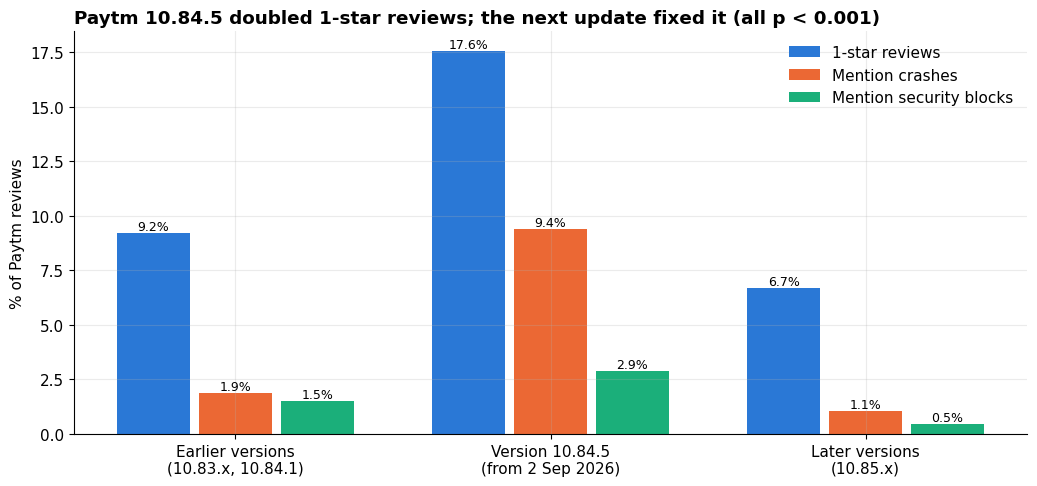

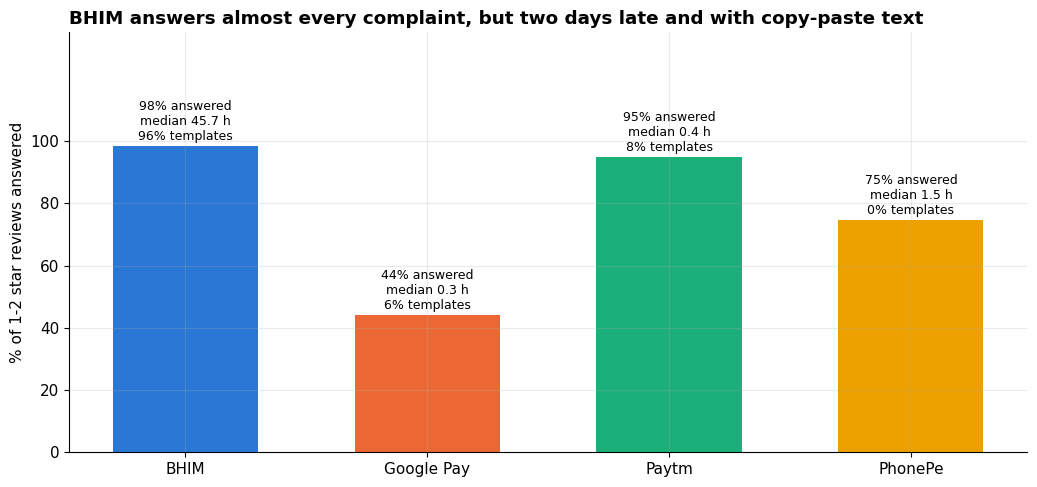

['01_rating_distribution.png', '02_length_by_rating.png', '03_weekly_trends.png', '07_theme_heatmap.png', '08_themes_over_time.png', '09_rating_drivers.png', '10_priority_matrix.png', '11_theme_heatmap_specific.html', '11_theme_heatmap_specific.png', '12_model_comparison.png', '13_paytm_release_event.png', '14_complaint_replies.png']


In [16]:
# ===== Phase 9a – Final presentation charts (PNG for slides + interactive HTML) =====
# One fixed colour per app everywhere (colour-blind-checked palette); one hue light-to-dark for magnitudes.
!pip install -q plotly
import plotly.express as px
FIG = f'{BASE}/reports/figures'
APP_COLORS = {'BHIM': '#2a78d6', 'Google Pay': '#eb6834', 'Paytm': '#1baf7a', 'PhonePe': '#eda100'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.25, 'font.size': 11, 'axes.titleweight': 'bold'})

# 1) Theme heatmap of SPECIFIC complaints; the unspecified share is shown under each app name
tc = themes_cmp.merge(rev[['review_id', 'app']], on='review_id')
gen = (tc.theme == 'General dissatisfaction').groupby(tc.app).mean().mul(100)
spec = tc[tc.theme != 'General dissatisfaction']
hm = pd.crosstab(spec.theme, spec.app, normalize='columns').mul(100)[apps]
hm = hm.loc[hm.max(1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10.5, 8))
im = ax.imshow(hm.values, cmap='Blues', aspect='auto', vmin=0)
ax.set_xticks(range(4)); ax.set_xticklabels([f'{a}\n({gen[a]:.0f}% unspecified)' for a in apps])
ax.set_yticks(range(len(hm))); ax.set_yticklabels(hm.index); ax.grid(False)
for i in range(hm.shape[0]):
    for j in range(4):
        v = hm.values[i, j]
        ax.text(j, i, f'{v:.0f}%', ha='center', va='center', fontsize=9, color='white' if v > 20 else '#0b0b0b')
ax.set_title("Each app has a different #1 problem\nShare of each app's specific complaints by theme", loc='left')
plt.colorbar(im, ax=ax, label='% of specific complaints'); plt.tight_layout()
plt.savefig(f'{FIG}/11_theme_heatmap_specific.png', dpi=200); plt.show()
px.imshow(hm.round(1), text_auto=True, color_continuous_scale='Blues', aspect='auto',
          title="Share of each app's specific complaints by theme (%)").write_html(f'{FIG}/11_theme_heatmap_specific.html')

# 2) Model comparison (macro F1 on the test set)
res = pd.read_csv(f'{BASE}/reports/model_results.csv')
order = ['VADER', 'TF-IDF + LogReg', 'Embeddings MiniLM-en + LogReg', 'Embeddings MiniLM-multilingual + LogReg', 'DistilBERT (fine-tuned)']
short = ['VADER\n(rules)', 'TF-IDF +\nLogReg', 'Embeddings EN\n+ LogReg', 'Embeddings multi\n+ LogReg', 'DistilBERT\n(fine-tuned)']
piv = res.pivot(index='model', columns='task', values='macro_f1').loc[order]
x, w = np.arange(len(order)), 0.38
fig, ax = plt.subplots(figsize=(10.5, 5))
for k, (task, col) in enumerate([('3-class', '#2a78d6'), ('2-class', '#eb6834')]):
    bars = ax.bar(x + (k - 0.5) * w, piv[task], w - 0.04, color=col, label=task)
    for i in [0, len(order) - 1]:                      # label only the first and the best model
        ax.text(bars[i].get_x() + bars[i].get_width() / 2, piv[task].iloc[i] + 0.01, f'{piv[task].iloc[i]:.2f}', ha='center', fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(short); ax.set_ylim(0, 1); ax.set_ylabel('Macro F1 (test set)')
ax.set_title('Fine-tuned DistilBERT beats every baseline on both tasks', loc='left'); ax.legend(title='Task', frameon=False)
plt.tight_layout(); plt.savefig(f'{FIG}/12_model_comparison.png', dpi=200); plt.show()

# 3) Paytm version 10.84.5 event
pv = summ.loc[['earlier versions', TARGET, 'later versions'], ['pct_1_star', 'pct_crash_mention', 'pct_security_mention']]
pv.columns = ['1-star reviews', 'Mention crashes', 'Mention security blocks']
fig, ax = plt.subplots(figsize=(10.5, 5))
x, w = np.arange(3), 0.26
for k, (c, col) in enumerate(zip(pv.columns, ['#2a78d6', '#eb6834', '#1baf7a'])):
    bars = ax.bar(x + (k - 1) * w, pv[c], w - 0.03, color=col, label=c)
    ax.bar_label(bars, fmt='%.1f%%', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(['Earlier versions\n(10.83.x, 10.84.1)', 'Version 10.84.5\n(from 2 Sep 2026)', 'Later versions\n(10.85.x)'])
ax.set_ylabel('% of Paytm reviews'); ax.legend(frameon=False)
ax.set_title('Paytm 10.84.5 doubled 1-star reviews; the next update fixed it (all p < 0.001)', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/13_paytm_release_event.png', dpi=200); plt.show()

# 4) Replies to complaints
rp = replies.loc[apps]
fig, ax = plt.subplots(figsize=(10.5, 5))
bars = ax.bar(apps, rp['reply_rate_1_2_star_%'], color=[APP_COLORS[a] for a in apps], width=0.6)
for b, a in zip(bars, apps):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 2,
            f"{rp.loc[a, 'reply_rate_1_2_star_%']:.0f}% answered\nmedian {rp.loc[a, 'median_hours_1_2_star']:.1f} h\n{rp.loc[a, 'template_share_1_2_star_%']:.0f}% templates",
            ha='center', fontsize=9)
ax.set_ylim(0, 135); ax.set_yticks(range(0, 101, 20)); ax.set_ylabel('% of 1-2 star reviews answered')
ax.set_title('BHIM answers almost every complaint, but two days late and with copy-paste text', loc='left')
plt.tight_layout(); plt.savefig(f'{FIG}/14_complaint_replies.png', dpi=200); plt.show()
print(sorted(os.listdir(FIG)) if 'os' in dir() else 'saved')

## Streamlit dashboard (Phase 9b)

In [17]:
# ===== Phase 9b – Streamlit dashboard =====
# Cell D2: compact data file + supporting tables for the dashboard (everything lives in the dashboard folder)
import os, shutil
DASH = f'{BASE}/dashboard'
os.makedirs(DASH, exist_ok=True)
dash = rev[['review_id', 'app', 'review_date', 'rating', 'review_text', 'bert_label', 'app_version',
            'helpful_votes', 'company_reply', 'reply_date']].merge(themes_cmp, on='review_id', how='left')
dash['is_complaint'] = (dash.rating <= 2) | (dash.bert_label == 'negative')
dash['replied'] = dash.company_reply.notna()
dash['reply_hours'] = ((pd.to_datetime(dash.reply_date) - pd.to_datetime(dash.review_date)).dt.total_seconds() / 3600).round(1)
dash = dash.drop(columns=['company_reply', 'reply_date'])
dash.to_parquet(f'{DASH}/dashboard_data.parquet', index=False)
for f in ['priority_matrix.csv', 'release_monitor.csv']:
    shutil.copy(f'{BASE}/reports/{f}', f'{DASH}/{f}')
with open(f'{DASH}/requirements.txt', 'w') as fh:
    fh.write('streamlit\npandas\npyarrow\nplotly\n')
print(dash.shape, '|', round(os.path.getsize(f'{DASH}/dashboard_data.parquet') / 1e6, 1), 'MB |', sorted(os.listdir(DASH)))

(85150, 12) | 6.1 MB | ['dashboard_data.parquet', 'priority_matrix.csv', 'release_monitor.csv', 'requirements.txt']


In [18]:
%%writefile /content/drive/MyDrive/upi-complaint-analytics/dashboard/app.py
"""UPI App Complaint Analytics - interactive dashboard (24INFS7101 capstone).
Run locally with:  streamlit run app.py"""
from pathlib import Path
import pandas as pd
import plotly.express as px
import streamlit as st

HERE = Path(__file__).parent
APPS = ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']
COLORS = {'BHIM': '#2a78d6', 'Google Pay': '#eb6834', 'Paytm': '#1baf7a', 'PhonePe': '#eda100'}

st.set_page_config(page_title='UPI Complaint Analytics', layout='wide')


@st.cache_data
def load():
    d = pd.read_parquet(HERE / 'dashboard_data.parquet')
    d['review_date'] = pd.to_datetime(d.review_date)
    return d, pd.read_csv(HERE / 'priority_matrix.csv'), pd.read_csv(HERE / 'release_monitor.csv')


df, pri, mon = load()

st.title('UPI App Complaint Analytics')
st.caption('Google Play reviews of BHIM, Google Pay, Paytm and PhonePe (May-Oct 2026), '
           'analysed with fine-tuned DistilBERT (sentiment) and BERTopic (complaint themes).')

with st.sidebar:
    st.header('Filters')
    apps = st.multiselect('Apps', APPS, default=APPS)
    dmin, dmax = df.review_date.min().date(), df.review_date.max().date()
    dates = st.date_input('Date range', (dmin, dmax), min_value=dmin, max_value=dmax)
    stars = st.slider('Star rating', 1, 5, (1, 5))

if not apps:
    st.warning('Select at least one app.')
    st.stop()
d0, d1 = dates if isinstance(dates, (list, tuple)) and len(dates) == 2 else (dmin, dmax)
f = df[df.app.isin(apps) & df.review_date.dt.date.between(d0, d1) & df.rating.between(*stars)]
if f.empty:
    st.info('No reviews match these filters.')
    st.stop()

comp = f[f.is_complaint]
named = comp[comp.theme.notna() & (comp.theme != 'General dissatisfaction')]
k = st.columns(5)
k[0].metric('Reviews', f'{len(f):,}')
k[1].metric('Average rating', f'{f.rating.mean():.2f} stars')
k[2].metric('Negative (model)', f"{(f.bert_label == 'negative').mean():.0%}")
k[3].metric('Top complaint theme', named.theme.mode().iat[0] if len(named) else '-')
k[4].metric('Complaints answered', f'{comp.replied.mean():.0%}' if len(comp) else '-')

t1, t2, t3, t4 = st.tabs(['Trends', 'Complaint themes', 'Releases', 'Review explorer'])

with t1:
    w = (f.groupby(['app', pd.Grouper(key='review_date', freq='W')])
          .agg(reviews=('rating', 'size'), avg_rating=('rating', 'mean'),
               negative=('bert_label', lambda s: (s == 'negative').mean() * 100))
          .reset_index())
    w = w[w.reviews >= 30]
    c1, c2 = st.columns(2)
    c1.plotly_chart(px.line(w, x='review_date', y='avg_rating', color='app', markers=True, color_discrete_map=COLORS,
                            labels={'review_date': 'Week', 'avg_rating': 'Average stars', 'app': 'App'},
                            title='Average star rating per week'), width='stretch')
    c2.plotly_chart(px.line(w, x='review_date', y='negative', color='app', markers=True, color_discrete_map=COLORS,
                            labels={'review_date': 'Week', 'negative': '% negative', 'app': 'App'},
                            title='Share of reviews the model reads as negative'), width='stretch')
    st.caption('Weeks with fewer than 30 reviews are hidden.')

with t2:
    themed = comp[comp.theme.notna()]
    if named.empty:
        st.info('No specific complaints in this selection.')
    else:
        share = (named.groupby(['app', 'theme']).size() / named.groupby('app').size()).mul(100).rename('share').reset_index()
        st.plotly_chart(px.bar(share, x='share', y='theme', color='app', barmode='group', orientation='h',
                               color_discrete_map=COLORS, height=650,
                               labels={'share': '% of specific complaints', 'theme': '', 'app': 'App'},
                               title='What do users complain about? (share of specific complaints)'), width='stretch')
        st.caption(f"{(themed.theme == 'General dissatisfaction').mean():.0%} of long complaints in this selection "
                   'name no specific problem and are not shown.')
    st.subheader('Fix priorities (whole dataset)')
    st.caption('Stars lost when a review mentions the theme, and the potential gain in average rating if fixed. '
               'Regression on all reviews; association, not proof of cause.')
    p = pri[pri.app.isin(apps) & (pri.reviews_mentioning >= 30)].sort_values(['app', 'gain_if_fixed'], ascending=[True, False])
    st.dataframe(p.groupby('app').head(5)[['app', 'theme', 'prevalence_%', 'stars_effect', 'gain_if_fixed']],
                 hide_index=True, width='stretch')

with t3:
    st.caption('Versions with 300+ reviews compared with the rest of the same app '
               '(Mann-Whitney test, Bonferroni-corrected).')
    m = mon[mon.app.isin(apps)].copy()
    m['label'] = m.app + ' ' + m.version.str.replace(r' \(.*\)', '', regex=True)
    m = m.sort_values('diff')
    st.plotly_chart(px.bar(m, x='diff', y='label', color='app', orientation='h', color_discrete_map=COLORS, height=750,
                           hover_data=['first_seen', 'reviews', 'avg_rating', 'mentions_rising_most', 'significant'],
                           labels={'diff': 'Rating difference vs rest of the app (stars)', 'label': '', 'app': 'App'},
                           title='Which releases were rated worse?'), width='stretch')
    st.markdown('**Significantly worse releases**')
    st.dataframe(m[m.significant][['app', 'version', 'first_seen', 'reviews', 'avg_rating', 'rest_of_app', 'diff',
                                   'mentions_rising_most']], hide_index=True, width='stretch')

with t4:
    q = st.text_input('Search review text (e.g. otp, refund, security alert)')
    th = st.multiselect('Complaint theme', sorted(f.theme.dropna().unique()))
    e = f
    if q:
        e = e[e.review_text.str.contains(q, case=False, na=False, regex=False)]
    if th:
        e = e[e.theme.isin(th)]
    st.write(f'{len(e):,} reviews - showing the 200 most helpful')
    st.dataframe(e.sort_values('helpful_votes', ascending=False).head(200)[
                     ['app', 'review_date', 'rating', 'bert_label', 'theme', 'helpful_votes', 'review_text']],
                 hide_index=True, width='stretch',
                 column_config={'review_text': st.column_config.TextColumn('Review', width='large')})

Writing /content/drive/MyDrive/upi-complaint-analytics/dashboard/app.py


In [19]:
# Cell D4: automated test – run the dashboard headlessly and check for errors (no browser needed)
!pip install -q streamlit
from streamlit.testing.v1 import AppTest
at = AppTest.from_file(f'{DASH}/app.py', default_timeout=180).run()
print('Exceptions:', [e.message for e in at.exception] or 'none')
print('KPIs:', [(m.label, m.value) for m in at.metric])
print('Tabs:', [t.label for t in at.tabs])
at.sidebar.multiselect[0].set_value(['Paytm']).run()          # simulate a user filtering to one app
print('After filtering to Paytm -> exceptions:', [e.message for e in at.exception] or 'none',
      '| KPIs:', [(m.label, m.value) for m in at.metric])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 25.6 MB/s eta 0:00:00


2026-10-20 15:42:15.741 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Exceptions: none
KPIs: [('Reviews', '85,150'), ('Average rating', '4.12 stars'), ('Negative (model)', '18%'), ('Top complaint theme', 'Registration, OTP & SIM verification'), ('Complaints answered', '77%')]
Tabs: ['Trends', 'Complaint themes', 'Releases', 'Review explorer']
After filtering to Paytm -> exceptions: none | KPIs: [('Reviews', '27,329'), ('Average rating', '4.45 stars'), ('Negative (model)', '12%'), ('Top complaint theme', 'Security / device-integrity blocks'), ('Complaints answered', '95%')]
